# Personalized Fashion Discovery: Balancing Relevance and Diversity
## Goal
Build and evaluate a recommender system 
## Dataset
H&M Personalized Fashion Recommendations (Kaggle competition), CSV format.
Files used: `transactions_train.csv`, `customers.csv`, `articles.csv`.
The `images/` folder is not used. Purchases are treated as implicit feedback.

## How to run
1. Accept the competition rules on kaggle.com for your own account.
2. Set your Kaggle API token as the environment variable `KAGGLE_API_TOKEN`.
3. Run all cells top to bottom. The first run downloads about 30 GB of data.

## Notebook map
1. Data acquisition and inspection
2. Preprocessing (missing values, exploration, temporal split, training window, activity filter, encoding)
3. Exploratory data analysis
4. Popularity baseline
5. ALS matrix factorization
6. Content-aware hybrid
7. MMR diversity re-ranking
8. Final comparison, timings, example, trade-offs, where each model struggles
9. Limitations and conclusions

## 1. Data Acquisition and Inspection

The data comes from the H&M Kaggle competition. This section downloads it, loads the three CSV files, and inspects their size, column types and missing values before any cleaning.

### 1.1 Download and Load the Data

`kagglehub` downloads the competition files into a local cache, so the notebook works on any machine with a Kaggle token. The first run downloads about 30 GB; later runs reuse the cache.

In [1]:
!pip install kagglehub

In [2]:
# !pip install kagglehub implicit

import os
import time
from itertools import islice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares

# Download (or reuse the cached copy of) the competition files.
data_path = kagglehub.competition_download('h-and-m-personalized-fashion-recommendations')

# transactions_train.csv: one row per purchase (date, customer, article, price, channel)
# customers.csv: one row per customer; articles.csv: one row per product
transactions = pd.read_csv(os.path.join(data_path, "transactions_train.csv"))
customers = pd.read_csv(os.path.join(data_path, "customers.csv"))
articles = pd.read_csv(os.path.join(data_path, "articles.csv"))

print("transactions:", transactions.shape)
print("customers:", customers.shape)
print("articles:", articles.shape)


transactions: (31788324, 5)
customers: (1371980, 7)
articles: (105542, 25)


### 1.2 Size, Columns and Types

For each table: number of rows and columns, approximate memory use, and the data type of every column. A sample of rows shows what the values look like.

In [3]:
for name, df in [("transactions", transactions),
                 ("customers", customers),
                 ("articles", articles)]:
    # Rows x columns, and memory use (a lower bound: text columns take more than shown).
    print(f"\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns, "
          f"at least {df.memory_usage().sum() / 1e9:.2f} GB in memory")
    # Data type of every column (object = text).
    print(df.dtypes.to_string())

# A peek at the first rows of the two smaller-width tables.
display(transactions.head())
display(customers.head())


transactions: 31,788,324 rows x 5 columns, at least 1.27 GB in memory
t_dat                object
customer_id          object
article_id            int64
price               float64
sales_channel_id      int64

customers: 1,371,980 rows x 7 columns, at least 0.08 GB in memory
customer_id                object
FN                        float64
Active                    float64
club_member_status         object
fashion_news_frequency     object
age                       float64
postal_code                object

articles: 105,542 rows x 25 columns, at least 0.02 GB in memory
article_id                       int64
product_code                     int64
prod_name                       object
product_type_no                  int64
product_type_name               object
product_group_name              object
graphical_appearance_no          int64
graphical_appearance_name       object
colour_group_code                int64
colour_group_name               object
perceived_colour_value_id    

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


### 1.3 Missing Values

Count of missing values per column, for all three tables. Only columns with at least one missing value are shown. Handling them is part of Section 2.

In [4]:
### Missing values
for name, df in [("transactions", transactions),
                 ("customers", customers),
                 ("articles", articles)]:
    # isna() marks each missing cell; sum() counts them per column.
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print(f"\n{name}: no missing values")
    else:
        # Show the count and the share of rows that are missing.
        summary = pd.DataFrame({"missing": missing,
                                "share of rows": (missing / len(df)).map("{:.1%}".format)})
        print(f"\n{name}:")
        print(summary.to_string())


transactions: no missing values

customers:
                        missing share of rows
FN                       895050         65.2%
Active                   907576         66.2%
club_member_status         6062          0.4%
fashion_news_frequency    16011          1.2%
age                       15861          1.2%

articles:
             missing share of rows
detail_desc      416          0.4%


### 1.4 Date Range and Scale

How much purchase history the data covers, how many customers and articles have at least one purchase, and how purchases are spread across years. This informs the choice of a recent subset in Section 2.

In [5]:
# Convert dates in a temporary variable only; the real conversion happens in Section 2.
dates = pd.to_datetime(transactions["t_dat"])

print("Date range:", dates.min().date(), "to", dates.max().date())
print("Customers with at least one purchase:", f"{transactions['customer_id'].nunique():,}")
print("Articles with at least one purchase:", f"{transactions['article_id'].nunique():,}")

print("\nTransactions per year:")
print(dates.dt.year.value_counts().sort_index().to_string())

Date range: 2018-09-20 to 2020-09-22
Customers with at least one purchase: 1,362,281
Articles with at least one purchase: 104,547

Transactions per year:
t_dat
2018     4411262
2019    16396930
2020    10980132


## 2. Preprocessing

This section prepares the data for modeling: missing values, the recent window, the temporal train/validation/test split, the activity filter, and encoding.

### 2.1 Handle Missing Values

Only `customers` and `articles` have gaps. The fill rules:
- `FN`, `Active`: filled with 0. These are newsletter/activity flags, and a missing value most likely means H&M never recorded one. H&M does not document them.
- `club_member_status`, `fashion_news_frequency`: filled with the label "unknown", so missingness stays visible as its own category.
- `age`: filled with the median, which is less affected by extreme ages than the mean.
- `detail_desc`: filled with an empty string. It is free text and is not used as a feature.

None of these columns is used by the models, so these choices do not affect the results.

In [6]:
# Look at the existing categories first, so the fill label doesn't collide with one.
print(customers["fashion_news_frequency"].value_counts().to_string())
print()
print(customers["club_member_status"].value_counts().to_string())

# Binary flags: missing most likely means "never recorded", so 0.
customers["FN"] = customers["FN"].fillna(0)
customers["Active"] = customers["Active"].fillna(0)

# Categorical columns: an explicit "unknown" label keeps missingness visible.
customers["fashion_news_frequency"] = customers["fashion_news_frequency"].fillna("unknown")
customers["club_member_status"] = customers["club_member_status"].fillna("unknown")

# Age is numeric; the median is a safer fill than the mean.
age_median = customers["age"].median()
customers["age"] = customers["age"].fillna(age_median)
print("\nMedian age used for the fill:", age_median)

# Free-text description: not used as a feature, so an empty string is fine.
articles["detail_desc"] = articles["detail_desc"].fillna("")

# Verify that no missing values remain.
print("\nMissing after filling:",
      customers.isna().sum().sum(), "in customers,",
      articles.isna().sum().sum(), "in articles,",
      transactions.isna().sum().sum(), "in transactions")

fashion_news_frequency
NONE         877711
Regularly    477416
Monthly         842

club_member_status
ACTIVE        1272491
PRE-CREATE      92960
LEFT CLUB         467

Median age used for the fill: 32.0

Missing after filling: 0 in customers, 0 in articles, 0 in transactions


### 2.2 Initial Exploration: Purchases Over Time

The date column is converted from text to real dates, and purchases are counted per calendar month. The first and last months are partial. This shows how the history is spread over time before the split and the training window are fixed in 2.3 and 2.4.

In [7]:
# Convert the date column from text to real dates; used from here on.
transactions["t_dat"] = pd.to_datetime(transactions["t_dat"])

# Purchases per calendar month across the whole history (the first and last months are partial).
monthly = transactions.groupby(transactions["t_dat"].dt.to_period("M")).size()
print("Purchases per month:")
print(monthly.to_string())

Purchases per month:
t_dat
2018-09     594776
2018-10    1397040
2018-11    1270619
2018-12    1148827
2019-01    1263471
2019-02    1152412
2019-03    1286750
2019-04    1476454
2019-05    1560319
2019-06    1906202
2019-07    1807494
2019-08    1253530
2019-09    1227178
2019-10    1146772
2019-11    1198033
2019-12    1118315
2020-01    1076354
2020-02    1001859
2020-03    1047752
2020-04    1340882
2020-05    1361815
2020-06    1764507
2020-07    1351502
2020-08    1237192
2020-09     798269
Freq: M


### 2.3 Temporal Split Dates

The split follows the global timeline: the last 14 days of the data are the test period, the 14 days before them are validation, and training uses purchases before the validation period. Evaluating on purchases later than anything the model has seen keeps the offline results realistic; splits that ignore the timeline can leak future information.

The dates depend only on the last date in the data, so they stay fixed whatever training window is chosen in 2.4.

In [8]:
# Fixed from the last date in the data; independent of the training window chosen in 2.4.
max_date = transactions["t_dat"].max()
test_start = max_date - pd.Timedelta(days=13)   # test = last 14 days, both ends included
val_start = test_start - pd.Timedelta(days=14)  # validation = the 14 days before the test period

periods = {
    "validation": (transactions["t_dat"] >= val_start) & (transactions["t_dat"] < test_start),
    "test": transactions["t_dat"] >= test_start,
}
for name, mask in periods.items():
    d = transactions.loc[mask, "t_dat"]
    print(f"{name}: {d.min().date()} to {d.max().date()}, {d.nunique()} days, {mask.sum():,} purchases")

# Order and length checks.
assert val_start < test_start <= max_date
assert transactions.loc[periods["validation"], "t_dat"].nunique() == 14
assert transactions.loc[periods["test"], "t_dat"].nunique() == 14
print("Training uses purchases before:", val_start.date())

validation: 2020-08-26 to 2020-09-08, 14 days, 547,838 purchases
test: 2020-09-09 to 2020-09-22, 14 days, 495,552 purchases
Training uses purchases before: 2020-08-26


### 2.4 Training Window

The training window is the last N months of purchases before the validation period starts, so it never includes validation or test purchases. The table compares candidate lengths by size and by how much history each customer has: the median number of purchases per customer, and the share of customers with at least 5 purchases, the activity threshold applied in 2.5.

N = 6 months is a provisional choice. Section 5 compares it with other lengths on the validation set, and the final value is fixed before the test set is used.

In [9]:
print(f"{'months':>6} {'start':>12} {'purchases':>12} {'customers':>11} {'articles':>10} {'median/cust':>12} {'share>=5':>9}")
for months in [3, 6, 9, 12]:
    start = val_start - pd.DateOffset(months=months)
    # Purchases from `start` up to the day before validation begins.
    w = transactions[(transactions["t_dat"] >= start) & (transactions["t_dat"] < val_start)]
    per_cust = w["customer_id"].value_counts()
    print(f"{months:>6} {str(start.date()):>12} {len(w):>12,} {len(per_cust):>11,} "
          f"{w['article_id'].nunique():>10,} {per_cust.median():>12.0f} {(per_cust >= 5).mean():>9.1%}")

# Provisional choice; Section 5 compares it with other lengths on validation.
WINDOW_MONTHS = 6
window_start = val_start - pd.DateOffset(months=WINDOW_MONTHS)
print("\nProvisional training window:", window_start.date(), "to", (val_start - pd.Timedelta(days=1)).date())

months        start    purchases   customers   articles  median/cust  share>=5
     3   2020-05-26    4,440,017     545,571     42,433            5     54.9%
     6   2020-02-26    8,013,981     738,262     50,379            6     61.3%
     9   2019-11-26   11,458,358     885,598     62,030            7     63.5%
    12   2019-08-26   14,828,066     986,864     69,627            8     65.2%

Provisional training window: 2020-02-26 to 2020-08-25


### 2.5 Activity Filter (training purchases only)

Customers and articles with very few purchases give a recommender little to learn from. The filter keeps customers and articles with at least MIN purchases in the training window, repeated until nobody falls below the minimum, since removing a customer can push an article under it and the other way round. Counts use training purchases only, so validation and test purchases play no part in who is kept.

The table shows how much survives at minimums of 3, 5 and 10. MIN = 5 is our choice for the default; no source sets it, and it has not been compared with other thresholds on validation. Customers who do not pass are not evaluated, so the results describe customers with at least 5 training purchases.

In [10]:
# Training purchases: the window, ending the day before validation starts.
train_window = transactions[(transactions["t_dat"] >= window_start) & (transactions["t_dat"] < val_start)]

def k_core(df, min_cust, min_art):
    # Repeat until every remaining customer and article has enough purchases (counted on df only).
    while True:
        before = len(df)
        c = df["customer_id"].value_counts()
        df = df[df["customer_id"].isin(c[c >= min_cust].index)]
        a = df["article_id"].value_counts()
        df = df[df["article_id"].isin(a[a >= min_art].index)]
        if len(df) == before:
            return df

n_cust_window = train_window["customer_id"].nunique()
print(f"Training window: {len(train_window):,} purchases, {n_cust_window:,} customers\n")
print(f"{'min':>4} {'customers':>10} {'% of cust':>10} {'articles':>9} {'purchases':>11} {'% of purch':>11}")

MIN_CUST = MIN_ART = 5
for m in [3, 5, 10]:
    kept = k_core(train_window, m, m)
    nc = kept["customer_id"].nunique()
    print(f"{m:>4} {nc:>10,} {nc / n_cust_window:>10.1%} {kept['article_id'].nunique():>9,} "
          f"{len(kept):>11,} {len(kept) / len(train_window):>11.1%}")
    if m == MIN_CUST:
        train_core = kept   # the training data used from here on

# Checks on the kept data.
assert train_core["customer_id"].value_counts().min() >= MIN_CUST
assert train_core["article_id"].value_counts().min() >= MIN_ART
assert train_core["t_dat"].max() < val_start
print("\nKept for training (min 5):",
      f"{train_core['customer_id'].nunique():,} customers,",
      f"{train_core['article_id'].nunique():,} articles,",
      f"{len(train_core):,} purchases")

Training window: 8,013,981 purchases, 738,262 customers

 min  customers  % of cust  articles   purchases  % of purch
   3    579,818      78.5%    40,025   7,756,982       96.8%
   5    451,552      61.2%    35,314   7,295,843       91.0%
  10    262,384      35.5%    28,413   5,980,540       74.6%

Kept for training (min 5): 451,552 customers, 35,314 articles, 7,295,843 purchases


### 2.6 Validation and Test Sets

The models learn from the training data kept in 2.5. They are scored on what customers bought in the validation period (used to choose settings) and in the test period (used once, at the end).

Evaluated customers are those with at least 5 training purchases, so the models have a history to work from. For each of them, the ground truth is every article they bought in the period, including articles that are not in the training data and articles they had already bought in training. The models do not recommend articles a customer already bought and cannot recommend articles outside the training data, so those purchases count as misses. Dropping them would make the scores look better by hiding what the models cannot do, so the share of each kind is reported instead.

In [11]:
# Periods are [start, end): validation = [val_start, test_start), test = [test_start, last day].
test_end = max_date + pd.Timedelta(days=1)

train_pairs = train_core[["customer_id", "article_id"]].drop_duplicates()
train_customers = set(train_core["customer_id"])
train_articles = set(train_core["article_id"])
window_customers = set(train_window["customer_id"])   # anyone with a purchase in the training window

def evaluation_truth(start, end, name):
    p = transactions[(transactions["t_dat"] >= start) & (transactions["t_dat"] < end)]
    pairs_all = p[["customer_id", "article_id"]].drop_duplicates()   # unique (customer, article) pairs

    # Customers who bought in this period, and how many of them the models know.
    in_period = set(pairs_all["customer_id"])
    evaluated = in_period & train_customers
    not_eval = in_period - train_customers
    print(f"{name}: {len(in_period):,} customers bought in this period")
    print(f"  evaluated (>= {MIN_CUST} training purchases): {len(evaluated):,} ({len(evaluated) / len(in_period):.1%})")
    print(f"  not evaluated: {len(not_eval):,} "
          f"({len(not_eval & window_customers):,} had some purchases in the training window, "
          f"{len(not_eval - window_customers):,} had none)")

    # Ground truth: ALL purchases of evaluated customers in the period.
    pairs = pairs_all[pairs_all["customer_id"].isin(evaluated)]
    m = pairs.merge(train_pairs, on=["customer_id", "article_id"], how="left", indicator=True)
    repeat = (m["_merge"] == "both").to_numpy()               # customer already bought it in training
    known = m["article_id"].isin(train_articles).to_numpy()   # article appears in the training data
    print(f"  purchases to predict: {len(pairs):,} ({len(pairs) / len(evaluated):.2f} per customer)")
    print(f"    repeat of the customer's own training purchase: {repeat.mean():.1%}")
    print(f"    new to the customer, article in the training data: {(~repeat & known).mean():.1%}   <- the only ones the models can hit")
    print(f"    article not in the training data: {(~known).mean():.1%}")
    return pairs.groupby("customer_id")["article_id"].apply(set)

val_truth = evaluation_truth(val_start, test_start, "Validation")
print()
test_truth = evaluation_truth(test_start, test_end, "Test")

val_customers = list(val_truth.index)
test_customers = list(test_truth.index)
assert set(val_customers) <= train_customers and set(test_customers) <= train_customers

Validation: 141,359 customers bought in this period
  evaluated (>= 5 training purchases): 93,354 (66.0%)
  not evaluated: 48,005 (22,456 had some purchases in the training window, 25,549 had none)
  purchases to predict: 349,525 (3.74 per customer)
    repeat of the customer's own training purchase: 2.8%
    new to the customer, article in the training data: 86.9%   <- the only ones the models can hit
    article not in the training data: 10.3%

Test: 128,333 customers bought in this period
  evaluated (>= 5 training purchases): 83,578 (65.1%)
  not evaluated: 44,755 (19,585 had some purchases in the training window, 25,170 had none)
  purchases to predict: 308,644 (3.69 per customer)
    repeat of the customer's own training purchase: 1.6%
    new to the customer, article in the training data: 68.7%   <- the only ones the models can hit
    article not in the training data: 29.7%


### 2.7 Encoding

Models work on integer positions, not on raw IDs or text labels, so two encodings are built, both from the training data only:
- **ID indices:** every training customer and article gets an integer index, used to build the user-item matrix for ALS in Section 5. Customers and articles outside the training data get no index; the models cannot score them.
- **Article attribute codes:** each article attribute (product type, department and colour group, plus five more) becomes integer category codes, used by the hybrid (Section 6) and MMR (Section 7) to compare articles.

Customer columns such as club status and news frequency are not encoded, and `price` and `age` are not scaled, because no model uses them.

In [12]:
# ID indices from the training data only; sorted so the numbering is reproducible.
cust_ids = np.sort(train_core["customer_id"].unique())
art_ids = np.sort(train_core["article_id"].unique())
cust_to_idx = {c: i for i, c in enumerate(cust_ids)}
art_to_idx = {a: i for i, a in enumerate(art_ids)}
print(f"{len(cust_ids):,} customers and {len(art_ids):,} articles indexed")

# Article attributes: the 3 from the proposal, plus 5 more kept for the check in Section 6.
base_attrs = ["product_type_name", "department_name", "colour_group_name"]
extra_attrs = ["garment_group_name", "section_name", "perceived_colour_master_name",
               "graphical_appearance_name", "index_group_name"]
all_attrs = base_attrs + extra_attrs

assert articles["article_id"].is_unique
art_attr = articles.set_index("article_id").loc[art_ids, all_attrs]   # same order as art_ids

codes, cats = {}, {}
for col in all_attrs:
    cat = art_attr[col].astype("category")
    codes[col] = cat.cat.codes.to_numpy()   # integer code per article; position = article index
    cats[col] = cat.cat.categories
    print(f"{col}: {len(cats[col])} categories among the indexed articles")

# Checks: no missing codes, and every evaluated customer has an index.
assert all((c >= 0).all() for c in codes.values())
assert all(c in cust_to_idx for c in val_customers + test_customers)

451,552 customers and 35,314 articles indexed
product_type_name: 118 categories among the indexed articles
department_name: 233 categories among the indexed articles
colour_group_name: 50 categories among the indexed articles
garment_group_name: 21 categories among the indexed articles
section_name: 55 categories among the indexed articles
perceived_colour_master_name: 20 categories among the indexed articles
graphical_appearance_name: 30 categories among the indexed articles
index_group_name: 5 categories among the indexed articles


## 3. Exploratory Data Analysis (EDA)

The EDA describes the training data only, so nothing in it is informed by validation or test purchases. It covers what the brief asks for: how customers and articles interact, how purchases are distributed, and which patterns stand out (popular items, active customers).

### 3.1 Interactions and Distributions

How sparse the customer-article matrix is, how many purchases each customer and article has, and how concentrated the activity is.

451,552 customers x 35,314 articles, 7,295,843 purchases, 6,280,525 unique customer-article pairs
Sparsity (share of customer-article pairs never bought): 99.9606%

Purchases per customer:
count    451552.0
mean         16.2
std          16.0
min           5.0
25%           7.0
50%          11.0
75%          19.0
max         625.0

Purchases per article:
count    35314.0
mean       206.6
std        456.7
min          5.0
25%         15.0
50%         51.0
75%        192.0
max      10310.0

Top 1% of articles account for 16.1% of purchases
Top 10% of articles account for 59.0% of purchases
Top 20% of articles account for 77.3% of purchases
Top 1% of customers account for 6.9% of purchases
Top 10% of customers account for 32.2% of purchases


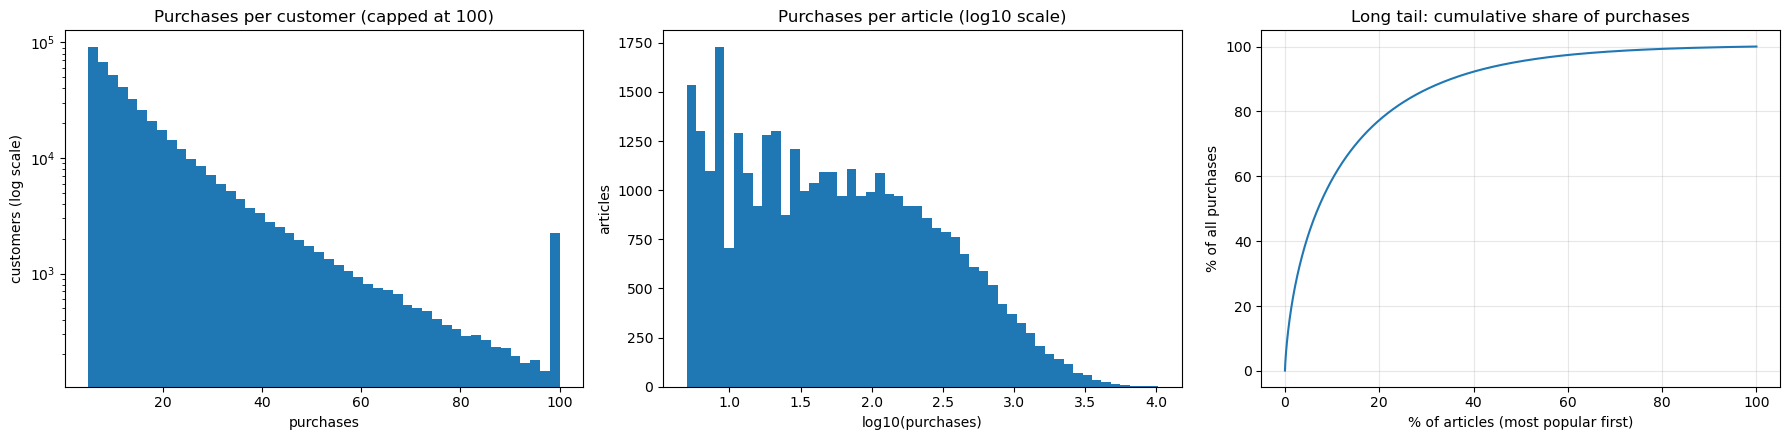

In [13]:
# EDA uses the training data only.
eda = train_core

n_users, n_items = eda["customer_id"].nunique(), eda["article_id"].nunique()
n_pairs = len(eda[["customer_id", "article_id"]].drop_duplicates())
print(f"{n_users:,} customers x {n_items:,} articles, {len(eda):,} purchases, "
      f"{n_pairs:,} unique customer-article pairs")
print(f"Sparsity (share of customer-article pairs never bought): {1 - n_pairs / (n_users * n_items):.4%}")

per_cust = eda["customer_id"].value_counts()   # purchases per customer, largest first
per_art = eda["article_id"].value_counts()     # purchases per article, largest first
print("\nPurchases per customer:\n" + per_cust.describe().round(1).to_string())
print("\nPurchases per article:\n" + per_art.describe().round(1).to_string())

# Concentration: share of all purchases made by the top X% of articles and customers.
art_cum = per_art.cumsum() / per_art.sum()
cust_cum = per_cust.cumsum() / per_cust.sum()
print()
for pct in [1, 10, 20]:
    print(f"Top {pct}% of articles account for {art_cum.iloc[int(len(per_art) * pct / 100) - 1]:.1%} of purchases")
for pct in [1, 10]:
    print(f"Top {pct}% of customers account for {cust_cum.iloc[int(len(per_cust) * pct / 100) - 1]:.1%} of purchases")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(per_cust.clip(upper=100), bins=48)   # capped at 100 so the long tail doesn't squash the plot
axes[0].set_yscale("log")
axes[0].set(title="Purchases per customer (capped at 100)", xlabel="purchases", ylabel="customers (log scale)")
axes[1].hist(np.log10(per_art), bins=50)
axes[1].set(title="Purchases per article (log10 scale)", xlabel="log10(purchases)", ylabel="articles")
axes[2].plot(np.arange(1, len(per_art) + 1) / len(per_art) * 100, art_cum.to_numpy() * 100)
axes[2].set(title="Long tail: cumulative share of purchases", xlabel="% of articles (most popular first)",
            ylabel="% of all purchases")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150, bbox_inches="tight")   # reused in the PDF report
plt.show()

### 3.2 Interaction Heatmap and Catalogue

A heatmap of the 100 most active customers against the 100 most popular articles, which are the densest corner of the matrix, shows how sparse the interactions are. The bar charts show which product types, colours and departments account for the most training purchases, followed by the best-selling individual articles.

Heatmap density: 5.73% of the 100 x 100 cells, versus 0.0394% of all pairs


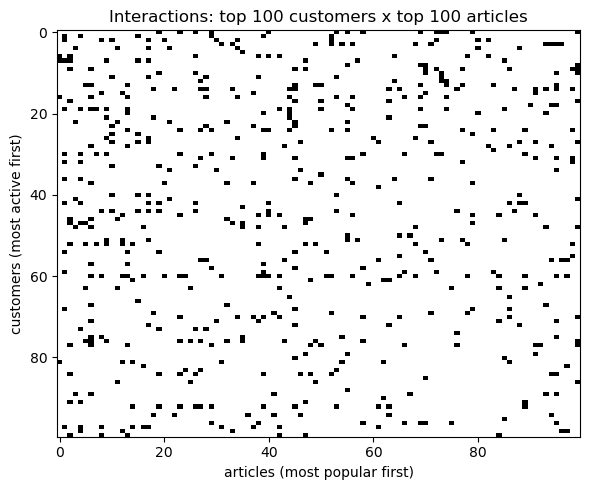

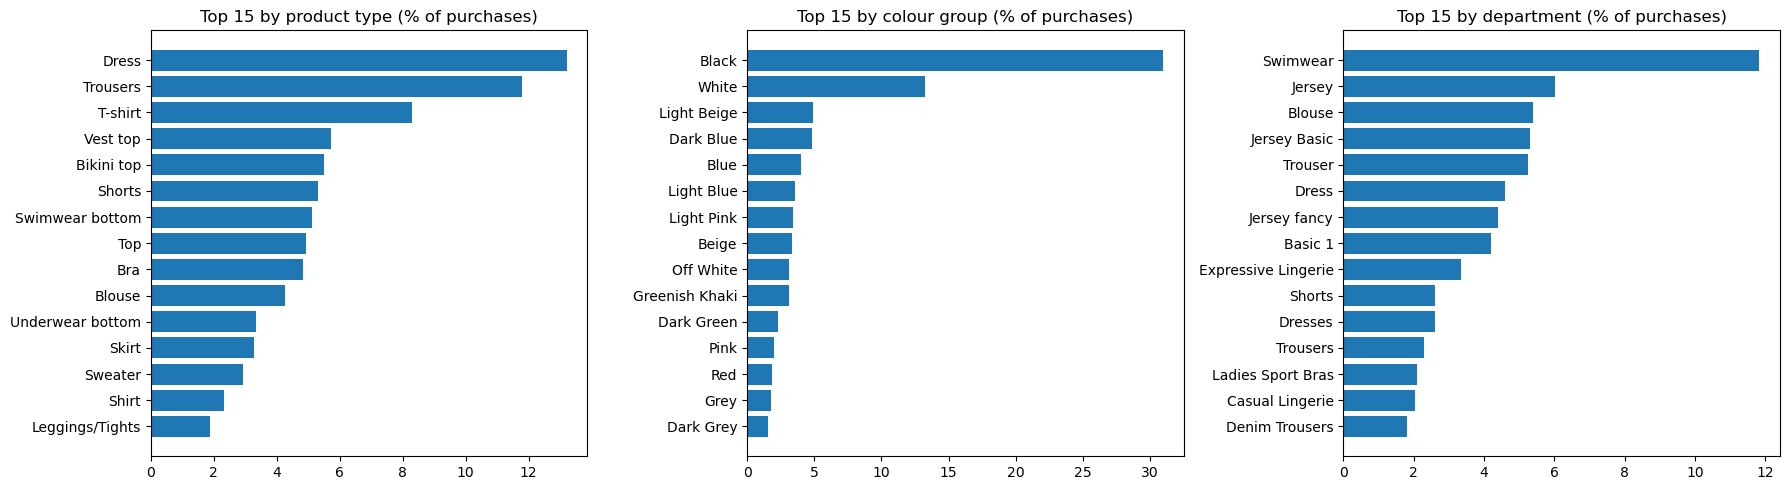

10 best-selling articles in the training data:
 article_id                prod_name product_type_name colour_group_name  purchases
  706016001 Jade HW Skinny Denim TRS          Trousers             Black      10310
  610776002                Tilly (1)           T-shirt             Black      10236
  759871002               Tilda tank          Vest top             Black       9393
  599580038   Timeless Midrise Brief   Swimwear bottom               Red       8809
  610776001                Tilly (1)           T-shirt             White       8777
  599580055   Timeless Midrise Brief   Swimwear bottom        Dark Green       8636
  841383002           Vanessa 2-pack          Vest top             Black       8110
  372860002       7p Basic Shaftless             Socks             White       7869
  741356002         Pamela Shorts HW            Shorts              Blue       7546
  372860001       7p Basic Shaftless             Socks             Black       7320

Sales channel share of purch

In [14]:
# Heatmap: 100 most active customers x 100 most popular articles (dark = bought at least once).
top_c, top_a = per_cust.index[:100], per_art.index[:100]
sub = eda[eda["customer_id"].isin(top_c) & eda["article_id"].isin(top_a)]
mat = pd.crosstab(sub["customer_id"], sub["article_id"]).reindex(index=top_c, columns=top_a, fill_value=0)
print(f"Heatmap density: {(mat.to_numpy() > 0).mean():.2%} of the 100 x 100 cells, "
      f"versus {n_pairs / (n_users * n_items):.4%} of all pairs")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(mat.to_numpy() > 0, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set(title="Interactions: top 100 customers x top 100 articles",
       xlabel="articles (most popular first)", ylabel="customers (most active first)")
plt.tight_layout()
plt.savefig("eda_interactions.png", dpi=150, bbox_inches="tight")
plt.show()

# Purchases per article joined to attributes (35,314 rows, so the join is small).
art_df = (per_art.rename("purchases").rename_axis("article_id").reset_index()
          .merge(articles[["article_id", "prod_name", "product_type_name",
                           "colour_group_name", "department_name"]], on="article_id", how="left"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["product_type_name", "colour_group_name", "department_name"]):
    top = art_df.groupby(col)["purchases"].sum().sort_values(ascending=False).head(15)
    ax.barh(top.index[::-1], (top / art_df["purchases"].sum() * 100).to_numpy()[::-1])
    ax.set(title=f"Top 15 by {col.replace('_name', '').replace('_', ' ')} (% of purchases)")
plt.tight_layout()
plt.savefig("eda_catalogue.png", dpi=150, bbox_inches="tight")
plt.show()

print("10 best-selling articles in the training data:")
print(art_df.head(10)[["article_id", "prod_name", "product_type_name",
                       "colour_group_name", "purchases"]].to_string(index=False))
print("\nSales channel share of purchases:")
print(eda["sales_channel_id"].value_counts(normalize=True).round(3).to_string())

In [15]:
for col in ["product_type_name", "colour_group_name", "department_name"]:
    s_ = art_df.groupby(col)["purchases"].sum().sort_values(ascending=False)
    print((s_.head(5) / s_.sum() * 100).round(1).to_string(), "\n")

product_type_name
Dress         13.2
Trousers      11.8
T-shirt        8.3
Vest top       5.7
Bikini top     5.5 

colour_group_name
Black          31.0
White          13.2
Light Beige     4.9
Dark Blue       4.8
Blue            4.0 

department_name
Swimwear        11.8
Jersey           6.0
Blouse           5.4
Jersey Basic     5.3
Trouser          5.2 



### 3.3 Customers, Time Patterns and Repeat Purchases

Who the customers are (age comes from the raw file, since the cleaned table has median-filled ages), how activity varies by age group and weekday, how the product mix changes month to month, and how many training purchases repeat a customer-article pair. Counts use the training data only; the first and last months of the window are partial.

Age missing for 0.5% of the 451,552 training customers
count    449480.0
mean         34.9
std          13.3
min          16.0
25%          24.0
50%          30.0
75%          47.0
max          99.0

Training purchases per customer by age group:
            count  mean  median
age_group                      
16-24      121126  14.3    10.0
25-34      150042  17.7    12.0
35-44       50585  17.6    12.0
45-54       81869  16.2    11.0
55-64       37752  15.0    10.0
65+          8106  13.1     9.0

Average purchases per day, by weekday:
Mon    35512
Tue    38127
Wed    46234
Thu    42525
Fri    40499
Sat    45119
Sun    32594

Share of each month's purchases (%), 6 most-bought product types:
product_type  Dress  Trousers  T-shirt  Vest top  Bikini top  Shorts
month                                                               
2020-02         8.3      14.7      6.4       3.2         3.1     1.0
2020-03         9.5      15.8      7.5       4.5         3.2     1.4
2020-04        12.4     

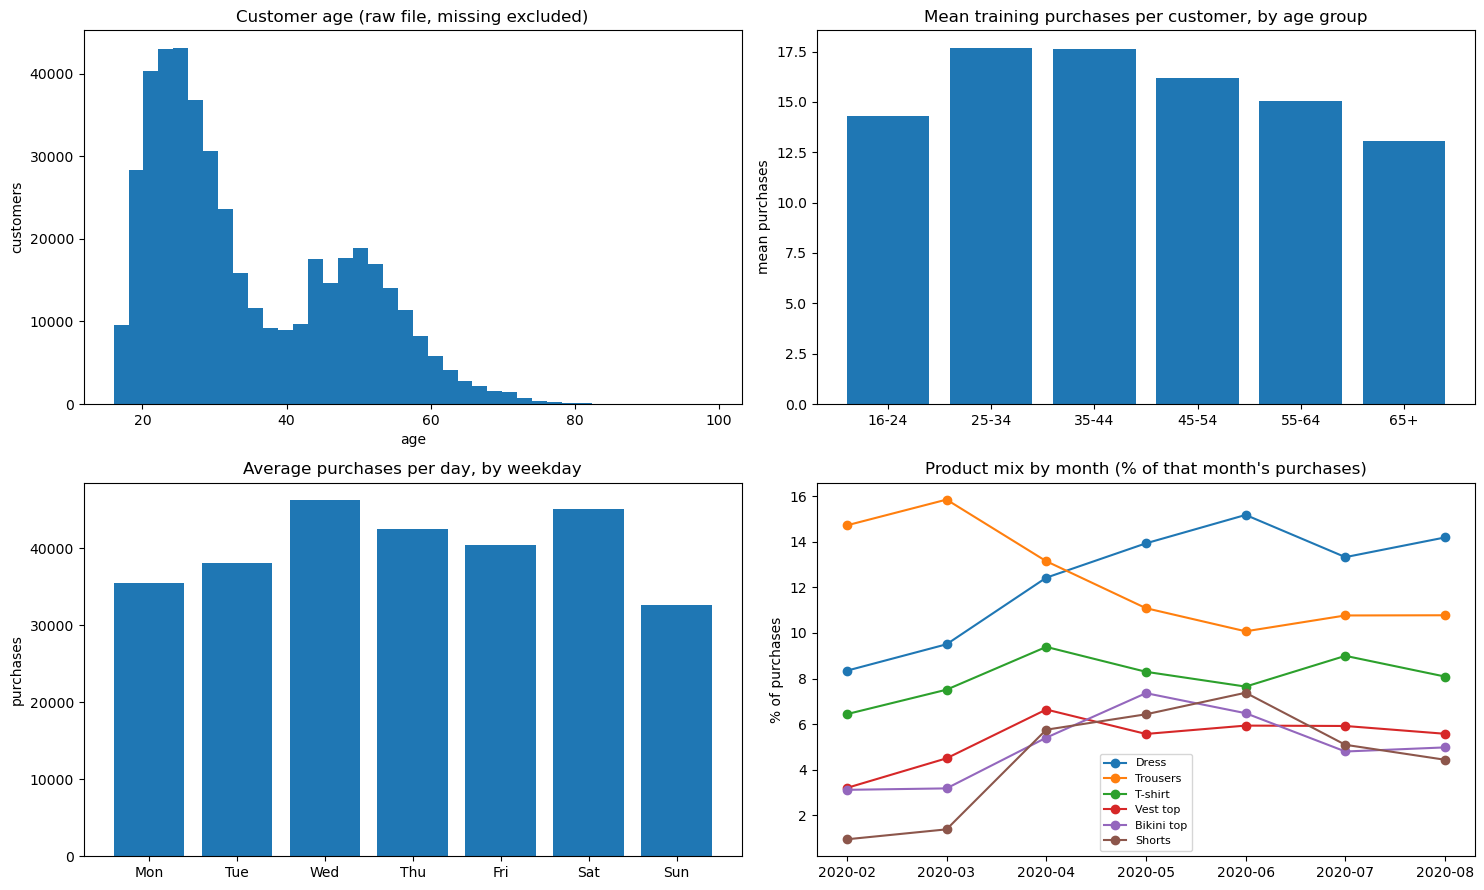

In [16]:
# --- Customers: age comes from the RAW file, because the cleaned table has median-filled ages (2.1).
raw_age = pd.read_csv(os.path.join(data_path, "customers.csv"), usecols=["customer_id", "age"])
cust_df = (per_cust.rename("purchases").rename_axis("customer_id").reset_index()
           .merge(raw_age, on="customer_id", how="left"))
print(f"Age missing for {cust_df['age'].isna().mean():.1%} of the {len(cust_df):,} training customers")
print(cust_df["age"].describe().round(1).to_string())

cust_df["age_group"] = pd.cut(cust_df["age"], bins=[15, 24, 34, 44, 54, 64, 120],
                              labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])
by_age = cust_df.groupby("age_group", observed=True)["purchases"].agg(["count", "mean", "median"])
print("\nTraining purchases per customer by age group:")
print(by_age.round(1).to_string())

# --- Time patterns (training data only).
daily = eda.groupby("t_dat").size()
dow = daily.groupby(daily.index.dayofweek).mean()          # average purchases per calendar day
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("\nAverage purchases per day, by weekday:")
print(dow.round(0).astype(int).to_string())

type_of = articles.set_index("article_id")["product_type_name"]
s = eda[["t_dat", "article_id"]].copy()
s["product_type"] = s["article_id"].map(type_of)
s["month"] = s["t_dat"].dt.to_period("M")
top_types = s["product_type"].value_counts().head(6).index
mix = pd.crosstab(s["month"], s["product_type"], normalize="index")[top_types] * 100
print("\nShare of each month's purchases (%), 6 most-bought product types:")
print(mix.round(1).to_string())
print("\nDays of data per month (first and last are partial):")
print(s.groupby("month")["t_dat"].nunique().to_string())

# --- Repeat purchases inside the training data.
repeats = len(eda) - n_pairs        # purchases beyond the first of each customer-article pair
same_day = eda.duplicated(["customer_id", "article_id", "t_dat"]).sum()
print(f"\n{repeats:,} of {len(eda):,} training purchases ({repeats / len(eda):.1%}) repeat a customer-article pair;")
print(f"{same_day:,} of those repeat on the same day")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].hist(cust_df["age"].dropna(), bins=40)
axes[0, 0].set(title="Customer age (raw file, missing excluded)", xlabel="age", ylabel="customers")
axes[0, 1].bar(by_age.index.astype(str), by_age["mean"])
axes[0, 1].set(title="Mean training purchases per customer, by age group", ylabel="mean purchases")
axes[1, 0].bar(dow.index, dow.to_numpy())
axes[1, 0].set(title="Average purchases per day, by weekday", ylabel="purchases")
for t in top_types:
    axes[1, 1].plot(mix.index.astype(str), mix[t].to_numpy(), marker="o", label=t)
axes[1, 1].set(title="Product mix by month (% of that month's purchases)", ylabel="% of purchases")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("eda_customers_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Popularity Baseline

The baseline gives every customer the same ranked list, skipping articles the customer already bought: the most purchased articles. It is the floor that every personalized model has to beat. This section also fixes the evaluation rules used for all models.

### 4.1 Evaluation Setup

- **Evaluated customers:** those with at least 5 training purchases who bought something in the period (2.6). The ground truth is every article they bought in the period, so recall counts purchases that no model can recommend.
- **Metrics, at K = 5, 10 and 12, averaged over customers:**
  - Precision@K: hits among the top K, divided by K.
  - Recall@K: hits among the top K, divided by the number of articles the customer bought in the period.
  - NDCG@K: a hit at rank r is worth 1/log2(r+1), normalized by the best possible ordering for that customer.
- **Rule for every model:** an article the customer already bought in training is never recommended again.
- **Settings are chosen on the validation set only.** The test set is scored once, in Section 8, with the settings frozen.
- The metric code is checked three ways: random lists must score about what chance predicts, a plain-Python calculation must match for one customer, and a perfect list must reach NDCG = 1.

In [17]:
import math

K_LIST = [5, 10, 12]
MAX_K = 12
DISCOUNT = 1.0 / np.log2(np.arange(2, MAX_K + 2))   # rank r (1..12) is worth 1/log2(r+1)

def hit_matrix(rec, truth_list):
    # rec: (customers, MAX_K) article ids, best first. truth_list: one set of article ids per customer.
    # H[i, j] = 1 if the article at rank j+1 for customer i was bought in the period.
    return np.array([[a in t for a in row] for row, t in zip(rec, truth_list)], dtype=np.int8)

def metrics(H, n_truth, ks=K_LIST):
    # n_truth = number of articles each customer bought in the period (the recall denominator).
    out = {}
    for k in ks:
        hits = H[:, :k].sum(axis=1)
        dcg = (H[:, :k] * DISCOUNT[:k]).sum(axis=1)
        ideal = np.cumsum(DISCOUNT[:k])[np.minimum(n_truth, k) - 1]   # best possible DCG per customer
        out[k] = {"P": (hits / k).mean(), "R": (hits / n_truth).mean(), "NDCG": (dcg / ideal).mean()}
    return out

def show(name, m):
    print(f"{name}: " + " | ".join(f"K={k}: P={v['P']:.4f} R={v['R']:.4f} NDCG={v['NDCG']:.4f}" for k, v in m.items()))

# Validation ground truth, in the same customer order as val_customers.
val_truth_list = [val_truth[c] for c in val_customers]
val_n = np.array([len(t) for t in val_truth_list])

# --- Sanity checks on the metric code (validation customers; nothing is tuned here) ---
rng = np.random.default_rng(0)
n_art = len(art_ids)

# Check 1: random lists should score about what chance predicts.
rand_rec = np.array([art_ids[rng.choice(n_art, MAX_K, replace=False)] for _ in val_customers])
H_rand = hit_matrix(rand_rec, val_truth_list)
m_rand = metrics(H_rand, val_n)
known = np.array([len(t & train_articles) for t in val_truth_list])   # purchases of articles in the training data
chance_p = known.mean() / n_art      # expected precision at any K for a uniform random list
print(f"Random list: P@12 = {m_rand[12]['P']:.5f}, expected by chance = {chance_p:.5f}")
assert 0.5 < m_rand[12]["P"] / chance_p < 1.5

# Check 2: the metric code against a plain-Python calculation for one customer.
i = int(H_rand.sum(axis=1).argmax())       # the random list with the most hits
row, n_i = H_rand[i], int(val_n[i])
hits_i = int(row.sum())
dcg_i = sum(1 / math.log2(r + 1) for r, h in enumerate(row, start=1) if h)
ideal_i = sum(1 / math.log2(r + 1) for r in range(1, min(n_i, MAX_K) + 1))
m1 = metrics(H_rand[i:i + 1], val_n[i:i + 1])[12]
print(f"Customer {i}: {hits_i} hit(s) in 12, {n_i} purchases | "
      f"vectorized P={m1['P']:.5f} R={m1['R']:.5f} NDCG={m1['NDCG']:.5f} | "
      f"manual P={hits_i / 12:.5f} R={hits_i / n_i:.5f} NDCG={dcg_i / ideal_i:.5f}")
assert abs(m1["P"] - hits_i / 12) < 1e-9 and abs(m1["R"] - hits_i / n_i) < 1e-9
assert abs(m1["NDCG"] - dcg_i / ideal_i) < 1e-9

# Check 3: a perfect list (the customer's own purchases first) must give NDCG = 1.
oracle = np.full((len(val_customers), MAX_K), -1, dtype=np.int64)    # -1 pads empty ranks
for j, t in enumerate(val_truth_list):
    items = list(t)[:MAX_K]
    oracle[j, :len(items)] = items
m_or = metrics(hit_matrix(oracle, val_truth_list), val_n)
exp_r12 = (np.minimum(val_n, MAX_K) / val_n).mean()
print(f"Perfect list: NDCG@12 = {m_or[12]['NDCG']:.4f}, Recall@12 = {m_or[12]['R']:.4f} (expected {exp_r12:.4f})")
assert abs(m_or[12]["NDCG"] - 1) < 1e-9 and abs(m_or[12]["R"] - exp_r12) < 1e-9

Random list: P@12 = 0.00009, expected by chance = 0.00010
Customer 1076: 1 hit(s) in 12, 4 purchases | vectorized P=0.08333 R=0.25000 NDCG=0.39038 | manual P=0.08333 R=0.25000 NDCG=0.39038
Perfect list: NDCG@12 = 1.0000, Recall@12 = 0.9928 (expected 0.9928)


### 4.2 Popularity Baselines

Popularity can be counted over the whole training window or only over its most recent weeks. The monthly product mix in 3.3 shifts through the window (for example Trousers fall from 15.8% in March to 10.1% in June, while Dress rises from 9.5% to 15.2%), so a recent window may suit the evaluation period better. Five windows are compared on validation, and the one with the highest Precision@12 is chosen before any test scoring. The whole-window version is kept as a reference.

In [18]:
# Articles each evaluated customer already bought in training; no model recommends them again.
eval_set = set(val_customers) | set(test_customers)
seen = (train_core[train_core["customer_id"].isin(eval_set)]
        .groupby("customer_id")["article_id"].apply(set))

def popularity_ranking(days):
    # Articles ranked by purchases in the last `days` days of training (None = the whole training window).
    d = train_core if days is None else train_core[train_core["t_dat"] >= val_start - pd.Timedelta(days=days)]
    return d["article_id"].value_counts().index.to_numpy()

def popularity_recs(ranking, customers, pool=300):
    # The same ranked list for everyone, skipping articles the customer already bought.
    top = ranking[:pool]
    rec = np.empty((len(customers), MAX_K), dtype=np.int64)
    for i, c in enumerate(customers):
        s = seen.get(c, set())
        rec[i] = list(islice((a for a in top if a not in s), MAX_K))   # errors if the pool runs out
    return rec

# Compare popularity windows on VALIDATION: the whole training window, then the last 8, 4, 2 and 1 weeks.
POP_DAYS_LIST = [None, 56, 28, 14, 7, 5, 3, 1]
val_H = {}
for days in POP_DAYS_LIST:
    val_H[days] = hit_matrix(popularity_recs(popularity_ranking(days), val_customers), val_truth_list)
    label = "whole window" if days is None else f"last {days} days"
    show(f"Popularity, {label}", metrics(val_H[days], val_n))

# Selection rule, fixed before looking: the window with the most hits in the top 12 (highest Precision@12).
POP_DAYS = max(POP_DAYS_LIST, key=lambda d: val_H[d][:, :12].sum())
print("\nChosen popularity window:", "whole window" if POP_DAYS is None else f"last {POP_DAYS} days")

# Paired difference against the whole-window version, with a rough +/- (2 standard errors).
if POP_DAYS is not None:
    d = (val_H[POP_DAYS][:, :12].sum(axis=1) - val_H[None][:, :12].sum(axis=1)) / 12
    print(f"Precision@12, chosen minus whole window: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

Popularity, whole window: K=5: P=0.0025 R=0.0033 NDCG=0.0042 | K=10: P=0.0023 R=0.0062 NDCG=0.0051 | K=12: P=0.0025 R=0.0083 NDCG=0.0059
Popularity, last 56 days: K=5: P=0.0051 R=0.0070 NDCG=0.0069 | K=10: P=0.0035 R=0.0095 NDCG=0.0073 | K=12: P=0.0033 R=0.0110 NDCG=0.0078
Popularity, last 28 days: K=5: P=0.0061 R=0.0092 NDCG=0.0085 | K=10: P=0.0043 R=0.0126 NDCG=0.0094 | K=12: P=0.0037 R=0.0128 NDCG=0.0095
Popularity, last 14 days: K=5: P=0.0058 R=0.0089 NDCG=0.0079 | K=10: P=0.0049 R=0.0147 NDCG=0.0100 | K=12: P=0.0046 R=0.0168 NDCG=0.0107
Popularity, last 7 days: K=5: P=0.0063 R=0.0101 NDCG=0.0084 | K=10: P=0.0055 R=0.0167 NDCG=0.0109 | K=12: P=0.0054 R=0.0199 NDCG=0.0120
Popularity, last 5 days: K=5: P=0.0062 R=0.0099 NDCG=0.0084 | K=10: P=0.0060 R=0.0184 NDCG=0.0117 | K=12: P=0.0057 R=0.0210 NDCG=0.0126
Popularity, last 3 days: K=5: P=0.0051 R=0.0076 NDCG=0.0068 | K=10: P=0.0057 R=0.0161 NDCG=0.0103 | K=12: P=0.0057 R=0.0201 NDCG=0.0117
Popularity, last 1 days: K=5: P=0.0050 R=0.0

In [19]:
# Is the chosen 1-day window really better than 5 or 7 days, or is the top of the curve flat?
for other in [5, 7]:
    d = (val_H[1][:, :12].sum(axis=1) - val_H[other][:, :12].sum(axis=1)) / 12
    print(f"Precision@12, 1 day minus {other} days: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

Precision@12, 1 day minus 5 days: +0.00023 (±0.00013)
Precision@12, 1 day minus 7 days: +0.00056 (±0.00014)


In [20]:
# Dates may be text again if the loading cell was re-run after 2.2; converting twice is harmless.
print("t_dat type before:", transactions["t_dat"].dtype)
transactions["t_dat"] = pd.to_datetime(transactions["t_dat"])

# Does counting popularity on ALL training-window purchases (not just the filtered data) change the baseline?
all_train = transactions[(transactions["t_dat"] >= window_start) & (transactions["t_dat"] < val_start)]

def ranking_all(days):
    d = all_train if days is None else all_train[all_train["t_dat"] >= val_start - pd.Timedelta(days=days)]
    return d["article_id"].value_counts().index.to_numpy()

print("Precision@12 on validation: popularity counted on the filtered data vs on all training purchases")
for days in [None, 7, 5, 1]:
    H_all = hit_matrix(popularity_recs(ranking_all(days), val_customers), val_truth_list)
    h_f, h_a = val_H[days][:, :12].sum(axis=1), H_all[:, :12].sum(axis=1)
    d = (h_a - h_f) / 12
    label = "whole window" if days is None else f"last {days} days"
    print(f"{label:13s} filtered={h_f.mean() / 12:.4f}  all={h_a.mean() / 12:.4f}  "
          f"all minus filtered: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

t_dat type before: datetime64[ns]
Precision@12 on validation: popularity counted on the filtered data vs on all training purchases
whole window  filtered=0.0025  all=0.0026  all minus filtered: +0.00006 (±0.00002)
last 7 days   filtered=0.0054  all=0.0054  all minus filtered: -0.00000 (±0.00001)
last 5 days   filtered=0.0057  all=0.0055  all minus filtered: -0.00019 (±0.00005)
last 1 days   filtered=0.0059  all=0.0057  all minus filtered: -0.00024 (±0.00008)


## 5. ALS Matrix Factorization

ALS (alternating least squares) learns a short vector of hidden taste factors for every customer and every article from the purchase matrix, and scores an article for a customer by how well the two vectors match. Unlike popularity, each customer gets their own list.

### 5.1 Training Matrix and Settings

The matrix has one row per training customer and one column per article, with a value for every pair bought at least once. Two ways of filling the value are compared: the number of purchases (a repeat counts more) or just 1 (bought or not). 13.9% of training purchases repeat a customer-article pair, 73.6% of those on the same day, which is why this choice is worth testing.

The number of factors and the regularization strength (which limits overfitting) are also varied, one setting at a time around a default. The number of iterations is fixed at 15 and not tuned. All six settings are compared on the validation set by Precision@12, and the highest is chosen before the test set is used. Articles a customer already bought in training are never recommended.

In [21]:
# Training matrix: rows = training customers, columns = articles, indexed as in 2.7.
tr = train_core[["customer_id", "article_id"]]
rows = tr["customer_id"].map(cust_to_idx).to_numpy()
cols = tr["article_id"].map(art_to_idx).to_numpy()

# csr_matrix adds up repeated (customer, article) entries, so each value = number of purchases.
counts = csr_matrix((np.ones(len(tr), dtype=np.float32), (rows, cols)),
                    shape=(len(cust_ids), len(art_ids)))
binary = counts.copy()
binary.data[:] = 1   # bought at least once
assert counts.nnz == n_pairs and int(round(counts.sum())) == len(tr)
print(f"Matrix {counts.shape[0]:,} x {counts.shape[1]:,}, {counts.nnz:,} filled cells, {len(tr):,} purchases")

# One setting changes at a time around the first (default) one.
configs = {
    "counts, 64 factors, reg 0.01":  dict(matrix="counts", factors=64,  regularization=0.01),
    "binary, 64 factors, reg 0.01":  dict(matrix="binary", factors=64,  regularization=0.01),
    "counts, 32 factors, reg 0.01":  dict(matrix="counts", factors=32,  regularization=0.01),
    "counts, 128 factors, reg 0.01": dict(matrix="counts", factors=128, regularization=0.01),
    "counts, 64 factors, reg 0.1":   dict(matrix="counts", factors=64,  regularization=0.1),
    "counts, 64 factors, reg 1.0":   dict(matrix="counts", factors=64,  regularization=1.0),
}

def als_recs(model, matrix, customers, batch=5000):
    # Top-12 articles per customer; articles already bought in training are filtered out.
    uidx = np.array([cust_to_idx[c] for c in customers])
    out = np.empty((len(uidx), MAX_K), dtype=np.int64)
    for s in range(0, len(uidx), batch):
        b = uidx[s:s + batch]
        ids, _ = model.recommend(b, matrix[b], N=MAX_K, filter_already_liked_items=True, recalculate_user=False)
        out[s:s + len(b)] = art_ids[ids]
    return out

res, best_name, best_hits = {}, None, -1
for name, cfg in configs.items():
    matrix = counts if cfg["matrix"] == "counts" else binary
    model = AlternatingLeastSquares(factors=cfg["factors"], regularization=cfg["regularization"],
                                    iterations=15, random_state=42)
    t0 = time.perf_counter()
    model.fit(matrix, show_progress=False)
    fit_s = time.perf_counter() - t0
    H = hit_matrix(als_recs(model, matrix, val_customers), val_truth_list)
    res[name] = {"H": H, "fit_s": fit_s}
    m = metrics(H, val_n)[12]
    print(f"{name:30s} fit {fit_s:4.0f}s  P@12={m['P']:.4f}  R@12={m['R']:.4f}  NDCG@12={m['NDCG']:.4f}")
    hits = H[:, :12].sum()
    if hits > best_hits:                       # selection rule: most hits in the top 12 on validation
        best_name, best_hits, als_model, als_matrix = name, hits, model, matrix

als_val_H = res[best_name]["H"]
print("\nChosen setting:", best_name)
show("ALS, validation", metrics(als_val_H, val_n))

# Paired differences against the popularity baselines from 4.2.
for label, ref in [(f"popularity, chosen window", val_H[POP_DAYS]), ("popularity, whole window", val_H[None])]:
    d = (als_val_H[:, :12].sum(axis=1) - ref[:, :12].sum(axis=1)) / 12
    print(f"Precision@12, ALS minus {label}: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

Matrix 451,552 x 35,314, 6,280,525 filled cells, 7,295,843 purchases


C:\Users\shrut\anaconda3\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: Intel MKL BLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'MKL_NUM_THREADS=1' or by callng 'threadpoolctl.threadpool_limits(1, "blas")'. Having MKL use a threadpool can lead to severe performance issues
  check_blas_config()


counts, 64 factors, reg 0.01   fit   20s  P@12=0.0026  R@12=0.0091  NDCG@12=0.0066
binary, 64 factors, reg 0.01   fit   21s  P@12=0.0024  R@12=0.0082  NDCG@12=0.0058
counts, 32 factors, reg 0.01   fit   19s  P@12=0.0028  R@12=0.0094  NDCG@12=0.0070
counts, 128 factors, reg 0.01  fit   32s  P@12=0.0026  R@12=0.0092  NDCG@12=0.0066
counts, 64 factors, reg 0.1    fit   20s  P@12=0.0026  R@12=0.0090  NDCG@12=0.0066
counts, 64 factors, reg 1.0    fit   20s  P@12=0.0026  R@12=0.0090  NDCG@12=0.0066

Chosen setting: counts, 32 factors, reg 0.01
ALS, validation: K=5: P=0.0037 R=0.0055 NDCG=0.0057 | K=10: P=0.0030 R=0.0085 NDCG=0.0067 | K=12: P=0.0028 R=0.0094 NDCG=0.0070
Precision@12, ALS minus popularity, chosen window: -0.00314 (±0.00018)
Precision@12, ALS minus popularity, whole window: +0.00028 (±0.00013)


### 5.2 Recency and Capacity Check

The ALS settings in 5.1 were compared on the validation set. Two further checks follow, because popularity counted over only the most recent days beat popularity over the whole window by a wide margin, and because the best factor count was the smallest tried:
- **Recency:** older purchases are given less weight. A purchase counts 0.5 ** (age / half-life), where age is the number of days before the validation period starts. Half-lives of 56, 28, 14 and 7 days are tried at 32 factors.
- **Capacity:** 8 and 16 factors, with plain purchase counts.

The setting with the most hits in the top 12 on the validation set is chosen, as in 5.1. This is the last ALS search; the result is reported whether or not it beats popularity.

In [22]:
# Weighted training matrix: a purchase counts 0.5 ** (age / half_life), age = days before validation starts.
# half_life = None keeps plain purchase counts, as in 5.1.
trw = train_core[["customer_id", "article_id", "t_dat"]]
u_idx = trw["customer_id"].map(cust_to_idx).to_numpy()
a_idx = trw["article_id"].map(art_to_idx).to_numpy()
age_days = (val_start - trw["t_dat"]).dt.days.to_numpy()
assert age_days.min() >= 1

def build_matrix(half_life):
    if half_life is None:
        w = np.ones(len(trw), dtype=np.float32)
    else:
        w = (0.5 ** (age_days / half_life)).astype(np.float32)
    M = csr_matrix((w, (u_idx, a_idx)), shape=(len(cust_ids), len(art_ids)))
    assert M.nnz == n_pairs
    return M

# Check: without decay this must equal the counts matrix from 5.1.
assert (build_matrix(None) != counts).nnz == 0

def fit_and_score(M, factors):
    model = AlternatingLeastSquares(factors=factors, regularization=0.01, iterations=15, random_state=42)
    t0 = time.perf_counter()
    model.fit(M, show_progress=False)
    fit_s = time.perf_counter() - t0
    H = hit_matrix(als_recs(model, M, val_customers), val_truth_list)
    return model, H, fit_s

# Reference: the 5.1 winner (counts, 32 factors, no decay).
best = ("counts, 32 factors, no decay (5.1 winner)", als_model, als_matrix, als_val_H, None, 32)
best_hits = als_val_H[:, :12].sum()
m = metrics(als_val_H, val_n)[12]
print(f"{best[0]:44s} P@12={m['P']:.4f}  R@12={m['R']:.4f}  NDCG@12={m['NDCG']:.4f}")

runs = [("counts, 8 factors, no decay", None, 8), ("counts, 16 factors, no decay", None, 16)]
runs += [(f"counts, 32 factors, half-life {hl} days", hl, 32) for hl in [56, 28, 14, 7]]
for name, hl, f in runs:
    M = build_matrix(hl)
    model, H, fit_s = fit_and_score(M, f)
    m = metrics(H, val_n)[12]
    print(f"{name:44s} P@12={m['P']:.4f}  R@12={m['R']:.4f}  NDCG@12={m['NDCG']:.4f}  (fit {fit_s:.0f}s)")
    if H[:, :12].sum() > best_hits:          # same rule as 5.1: most hits in the top 12 on validation
        best, best_hits = (name, model, M, H, hl, f), H[:, :12].sum()

# The winner becomes the ALS model used from here on (Sections 6 to 8).
name, als_model, als_matrix, als_val_H, ALS_HALF_LIFE, ALS_FACTORS = best
print("\nChosen:", name)
show("ALS, validation", metrics(als_val_H, val_n))
for label, ref in [("popularity, chosen window", val_H[POP_DAYS]), ("popularity, whole window", val_H[None])]:
    d = (als_val_H[:, :12].sum(axis=1) - ref[:, :12].sum(axis=1)) / 12
    print(f"Precision@12, ALS minus {label}: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

counts, 32 factors, no decay (5.1 winner)    P@12=0.0028  R@12=0.0094  NDCG@12=0.0070
counts, 8 factors, no decay                  P@12=0.0029  R@12=0.0096  NDCG@12=0.0071  (fit 16s)
counts, 16 factors, no decay                 P@12=0.0028  R@12=0.0095  NDCG@12=0.0070  (fit 18s)
counts, 32 factors, half-life 56 days        P@12=0.0031  R@12=0.0107  NDCG@12=0.0075  (fit 22s)
counts, 32 factors, half-life 28 days        P@12=0.0035  R@12=0.0121  NDCG@12=0.0087  (fit 22s)
counts, 32 factors, half-life 14 days        P@12=0.0043  R@12=0.0154  NDCG@12=0.0106  (fit 21s)
counts, 32 factors, half-life 7 days         P@12=0.0045  R@12=0.0158  NDCG@12=0.0104  (fit 22s)

Chosen: counts, 32 factors, half-life 7 days
ALS, validation: K=5: P=0.0050 R=0.0076 NDCG=0.0074 | K=10: P=0.0046 R=0.0137 NDCG=0.0096 | K=12: P=0.0045 R=0.0158 NDCG=0.0104
Precision@12, ALS minus popularity, chosen window: -0.00140 (±0.00018)
Precision@12, ALS minus popularity, whole window: +0.00202 (±0.00016)


## 6. Content-Aware Hybrid

### 6.1 Design

The hybrid keeps ALS as the source of candidates and uses article attributes to reorder them. For each customer:
1. ALS proposes its top 100 articles, each with a score.
2. **Taste profile:** for each of three attributes (product type, department, colour group), the share of the customer's training purchases that fall in each value. If 4 of 10 purchases were Sweaters, the profile gives Sweater 0.4.
3. **Content score** of a candidate: the average, over the three attributes, of the customer's share for the candidate's value. A candidate that matches what the customer usually buys scores high.
4. Both scores are rescaled to 0-1 across the customer's 100 candidates, because ALS scores have an arbitrary scale. The final score is α × ALS + (1 − α) × content. α = 1 is plain ALS and α = 0 is content alone.
5. The 12 highest final scores are recommended. Articles already bought in training are never candidates.

α is chosen on the validation set from 0.0 to 1.0 in steps of 0.1: the value with the most hits in the top 12 wins, and ties go to the larger α (closer to plain ALS). The hybrid is only kept if it beats plain ALS by more than the noise; the paired difference is reported. Profiles use all training purchases equally, while ALS weights recent purchases more, which is a known mismatch.

In [23]:
N_CAND = 100   # candidates per customer taken from ALS

def als_candidates(model, matrix, customers, batch=5000):
    # Top-N_CAND articles per customer (as article indices) with their raw ALS scores; already-bought ones are filtered out.
    uidx = np.array([cust_to_idx[c] for c in customers])
    cand = np.empty((len(uidx), N_CAND), dtype=np.int64)
    score = np.empty((len(uidx), N_CAND), dtype=np.float32)
    for s in range(0, len(uidx), batch):
        b = uidx[s:s + batch]
        ids, sc = model.recommend(b, matrix[b], N=N_CAND, filter_already_liked_items=True, recalculate_user=False)
        cand[s:s + len(b)], score[s:s + len(b)] = ids, sc
    return cand, score

val_cand, val_als = als_candidates(als_model, als_matrix, val_customers)
val_hit100 = hit_matrix(art_ids[val_cand], val_truth_list)    # 1 if the candidate was bought in the validation period

# Check: the first 12 candidates must be the same 12 articles ALS recommended in 5.2.
same = (art_ids[val_cand[:, :MAX_K]] == als_recs(als_model, als_matrix, val_customers)).all(axis=1).mean()
print(f"Top-12 identical to the 5.2 recommendations for {same:.2%} of customers")
assert same > 0.999

# Taste profiles: share of each customer's training purchases in each attribute value.
n_val = len(val_customers)
val_row = {c: i for i, c in enumerate(val_customers)}
trv = train_core[train_core["customer_id"].isin(set(val_customers))][["customer_id", "article_id"]]
ui = trv["customer_id"].map(val_row).to_numpy()
ai = trv["article_id"].map(art_to_idx).to_numpy()

profile = {}
for col in base_attrs:
    n_cat = len(cats[col])
    cnt = np.bincount(ui * n_cat + codes[col][ai], minlength=n_val * n_cat).reshape(n_val, n_cat).astype(np.float32)
    profile[col] = cnt / cnt.sum(axis=1, keepdims=True)
    assert np.allclose(profile[col].sum(axis=1), 1, atol=1e-4)

# Content score: average over the attributes of the customer's share for each candidate's value.
ridx = np.arange(n_val)[:, None]
content = np.zeros((n_val, N_CAND), dtype=np.float32)
for col in base_attrs:
    content += profile[col][ridx, codes[col][val_cand]]
content /= len(base_attrs)

def minmax(x):
    # Rescale each customer's 100 values to 0-1.
    lo, hi = x.min(axis=1, keepdims=True), x.max(axis=1, keepdims=True)
    return (x - lo) / (hi - lo + 1e-9)

als_n, cont_n = minmax(val_als), minmax(content)

# Sweep alpha on VALIDATION. Descending order, so ties go to the larger alpha.
alphas = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.0]
hyb_H = {}
print("alpha |  P@12    R@12   NDCG@12")
for a in alphas:
    order = np.argsort(-(a * als_n + (1 - a) * cont_n), axis=1, kind="stable")[:, :MAX_K]
    hyb_H[a] = np.take_along_axis(val_hit100, order, axis=1)
    m = metrics(hyb_H[a], val_n)[12]
    print(f"{a:4.1f}  | {m['P']:.4f}  {m['R']:.4f}  {m['NDCG']:.4f}")

# Check: alpha = 1 must reproduce plain ALS from 5.2.
p_als = metrics(als_val_H, val_n)[12]["P"]
assert abs(metrics(hyb_H[1.0], val_n)[12]["P"] - p_als) < 2e-5

HYB_ALPHA = max(alphas, key=lambda a: hyb_H[a].sum())    # most hits in the top 12
print("\nChosen alpha:", HYB_ALPHA)
show("Hybrid, validation", metrics(hyb_H[HYB_ALPHA], val_n))
d = (hyb_H[HYB_ALPHA].sum(axis=1) - hyb_H[1.0].sum(axis=1)) / MAX_K
print(f"Precision@12, hybrid (alpha={HYB_ALPHA}) minus ALS: {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")

Top-12 identical to the 5.2 recommendations for 100.00% of customers
alpha |  P@12    R@12   NDCG@12
 1.0  | 0.0045  0.0158  0.0104
 0.9  | 0.0047  0.0163  0.0107
 0.8  | 0.0047  0.0163  0.0108
 0.7  | 0.0048  0.0167  0.0111
 0.6  | 0.0047  0.0163  0.0110
 0.5  | 0.0046  0.0159  0.0110
 0.4  | 0.0045  0.0155  0.0108
 0.3  | 0.0044  0.0150  0.0103
 0.2  | 0.0043  0.0145  0.0098
 0.1  | 0.0042  0.0140  0.0094
 0.0  | 0.0041  0.0139  0.0092

Chosen alpha: 0.7
Hybrid, validation: K=5: P=0.0057 R=0.0085 NDCG=0.0081 | K=10: P=0.0049 R=0.0146 NDCG=0.0103 | K=12: P=0.0048 R=0.0167 NDCG=0.0111
Precision@12, hybrid (alpha=0.7) minus ALS: +0.00023 (±0.00010)


## 7. MMR Diversity Re-ranking

### 7.1 Design

MMR (Maximal Marginal Relevance) re-ranks a list so that it stays relevant but is less repetitive.

- **Base ranker:** the hybrid of Section 6. The proposal applies MMR to the best-performing model. Popularity over the last day leads on Precision@12 and Recall@12 at K = 10 and 12 on validation, but it gives every customer the same ranked list, skipping articles the customer already bought, so re-ranking it for variety is not a personalization question. The hybrid is the best personalized model, so MMR is applied to it. Section 8 compares all four methods on the test set.
- **Candidates and relevance:** the hybrid's 100 candidates per customer. Relevance is the hybrid score, rescaled to 0-1 across the customer's 100 candidates.
- **Similarity between two articles:** the share of three attributes they have in common (product type, department, colour group), so 0, 1/3, 2/3 or 1.
- **Selection:** 12 picks, one at a time. Each pick maximizes λ × relevance − (1 − λ) × (the highest similarity to any article already picked). λ = 1 is the hybrid unchanged; smaller λ trades relevance for variety.
- **λ values:** 1.0 down to 0.3 in steps of 0.1, compared on the validation set.
- **Diversity measure:** intra-list diversity = 1 − the average pairwise similarity within the 12 articles. It is reported two ways: with the attribute similarity above, which MMR optimizes directly so it rises almost by construction, and with the cosine similarity of the ALS item vectors, which MMR never sees and is therefore the fairer check.
- **Operating point:** the smallest λ whose Precision@12 stays within 5% of λ = 1 on validation. The 5% is our choice, so the whole curve is reported too. The test set is scored once, in Section 8.
- **Caveat:** the department list contains near-duplicate labels (for example "Trouser" and "Trousers"), which the similarity treats as different, so attribute diversity may be overstated.

In [24]:
LAMBDAS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3]

# Attribute codes per article (row = article index), used for the similarity between two articles.
attr_codes = np.stack([codes[c] for c in base_attrs], axis=1)

# Unit-length ALS item vectors, for a second diversity measure that MMR never optimizes.
item_vecs = np.asarray(als_model.item_factors, dtype=np.float32)
item_vecs = item_vecs / (np.linalg.norm(item_vecs, axis=1, keepdims=True) + 1e-9)
off_diag = ~np.eye(MAX_K, dtype=bool)    # ignore each article's similarity with itself

def ild(top, kind, chunk=20000):
    # Intra-list diversity = 1 - average pairwise similarity inside each list. top: (customers, 12) article indices.
    out = []
    for s in range(0, len(top), chunk):
        t = top[s:s + chunk]
        if kind == "attr":
            c = attr_codes[t]                                                    # (m, 12, 3)
            sim = (c[:, :, None, :] == c[:, None, :, :]).mean(axis=3, dtype=np.float32)
        else:
            v = item_vecs[t]                                                     # (m, 12, factors)
            sim = v @ v.transpose(0, 2, 1)                                       # cosine similarity
        out.append(1 - sim[:, off_diag].mean(axis=1))
    return np.concatenate(out)

# Check: the vectorized attribute ILD against a plain-Python calculation for one list.
c0 = attr_codes[val_cand[0, :MAX_K]]
manual = 1 - np.mean([np.mean(c0[i] == c0[j]) for i in range(MAX_K) for j in range(MAX_K) if i != j])
assert abs(ild(val_cand[:1, :MAX_K], "attr")[0] - manual) < 1e-6

def mmr_select(cand, rel, lambdas, chunk=2000):
    # Greedy MMR: each of the 12 picks maximizes lambda * relevance - (1 - lambda) * (highest similarity to a picked article).
    out = {lam: np.zeros((len(cand), MAX_K), dtype=np.int64) for lam in lambdas}
    for s in range(0, len(cand), chunk):
        e = min(s + chunk, len(cand)); m = e - s
        c = attr_codes[cand[s:e]]                                                      # (m, 100, 3)
        sim = (c[:, :, None, :] == c[:, None, :, :]).mean(axis=3, dtype=np.float32)    # (m, 100, 100) share of attributes in common
        r, rows = rel[s:e], np.arange(m)
        for lam in lambdas:
            chosen = np.zeros((m, N_CAND), dtype=bool)
            max_sim = np.zeros((m, N_CAND), dtype=np.float32)     # similarity to the closest article picked so far
            for step in range(MAX_K):
                score = lam * r - (1 - lam) * max_sim
                score[chosen] = -np.inf                           # never pick the same article twice
                pick = score.argmax(axis=1)
                out[lam][s:e, step] = pick
                chosen[rows, pick] = True
                max_sim = np.maximum(max_sim, sim[rows, pick, :])
    return out

# Relevance = the hybrid score (alpha chosen in Section 6), rescaled to 0-1 per customer.
rel_val = minmax(HYB_ALPHA * als_n + (1 - HYB_ALPHA) * cont_n)
sel = mmr_select(val_cand, rel_val, LAMBDAS)

H_by, st = {}, {}
for lam in LAMBDAS:
    H = np.take_along_axis(val_hit100, sel[lam], axis=1)
    top = np.take_along_axis(val_cand, sel[lam], axis=1)
    H_by[lam] = H
    m = metrics(H, val_n)[12]
    st[lam] = dict(P=m["P"], R=m["R"], N=m["NDCG"], a=ild(top, "attr").mean(), c=ild(top, "cos").mean())

# Check: lambda = 1.0 must reproduce the hybrid from Section 6.
p_h = metrics(hyb_H[HYB_ALPHA], val_n)[12]["P"]
print(f"check: lambda=1.0 P@12 = {st[1.0]['P']:.5f}, hybrid from Section 6 = {p_h:.5f}\n")
assert abs(st[1.0]["P"] - p_h) < 5e-5

print("lambda |  P@12    R@12  NDCG@12 | P@12 change vs lambda=1 (paired) | attr ILD | cos ILD")
for lam in LAMBDAS:
    d = (H_by[lam].sum(axis=1) - H_by[1.0].sum(axis=1)) / MAX_K
    print(f"{lam:5.1f}  | {st[lam]['P']:.4f}  {st[lam]['R']:.4f}  {st[lam]['N']:.4f} | "
          f"{d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})              | {st[lam]['a']:.4f}   | {st[lam]['c']:.4f}")

# Operating point, by the rule in the design: smallest lambda with Precision@12 within 5% of lambda = 1.
MMR_LAMBDA = min(l for l in LAMBDAS if st[l]["P"] >= 0.95 * st[1.0]["P"])
print("\nChosen lambda:", MMR_LAMBDA)

# Diversity of the other lists on validation, for context.
pop_rec = popularity_recs(popularity_ranking(POP_DAYS), val_customers)
pop_top = np.array([[art_to_idx[a] for a in row] for row in pop_rec])
print("\nIntra-list diversity of the other lists on validation (attribute / cosine):")
for name, top in [("Popularity, chosen window", pop_top), ("ALS", val_cand[:, :MAX_K])]:
    print(f"  {name:26s} {ild(top, 'attr').mean():.4f} / {ild(top, 'cos').mean():.4f}")

check: lambda=1.0 P@12 = 0.00477, hybrid from Section 6 = 0.00477

lambda |  P@12    R@12  NDCG@12 | P@12 change vs lambda=1 (paired) | attr ILD | cos ILD
  1.0  | 0.0048  0.0167  0.0111 | +0.00000 (±0.00000)              | 0.6647   | 0.3404
  0.9  | 0.0047  0.0166  0.0110 | -0.00004 (±0.00005)              | 0.7085   | 0.3542
  0.8  | 0.0046  0.0160  0.0106 | -0.00019 (±0.00008)              | 0.7618   | 0.3683
  0.7  | 0.0044  0.0155  0.0103 | -0.00034 (±0.00010)              | 0.8260   | 0.3769
  0.6  | 0.0041  0.0143  0.0097 | -0.00064 (±0.00011)              | 0.9003   | 0.3716
  0.5  | 0.0038  0.0132  0.0092 | -0.00098 (±0.00012)              | 0.9492   | 0.3515
  0.4  | 0.0035  0.0124  0.0087 | -0.00124 (±0.00013)              | 0.9715   | 0.3299
  0.3  | 0.0034  0.0120  0.0085 | -0.00136 (±0.00014)              | 0.9771   | 0.3188

Chosen lambda: 0.8

Intra-list diversity of the other lists on validation (attribute / cosine):
  Popularity, chosen window  0.6711 / 0.7304
  ALS  

### 7.2 Relevance vs Diversity Curve

Precision@12 against both diversity measures for each λ on the validation set, from the table above. The test set is scored only at the chosen λ, in Section 8. The figure is saved as `mmr_tradeoff.png` for the report.

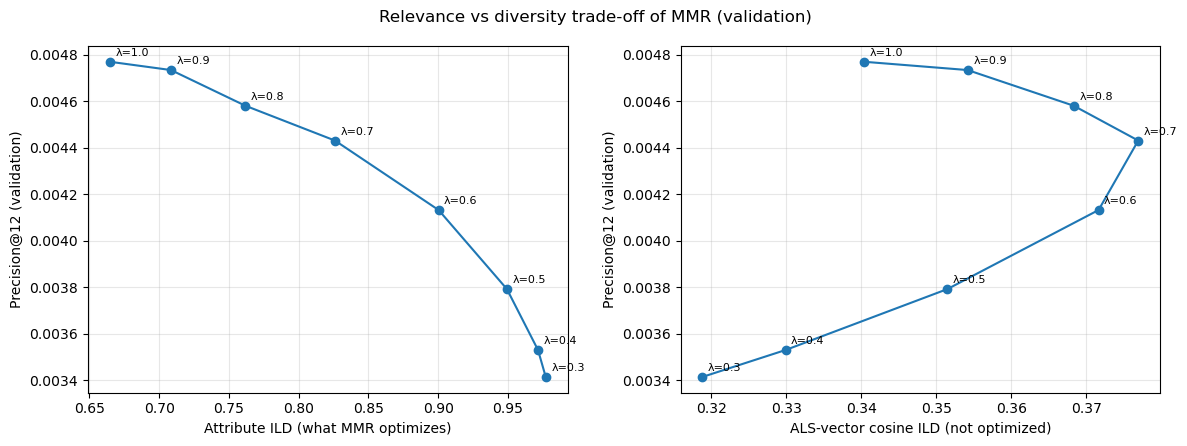

In [25]:
# Relevance vs diversity across lambda (validation). Each point is one lambda.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, key, xlabel in [(axes[0], "a", "Attribute ILD (what MMR optimizes)"),
                        (axes[1], "c", "ALS-vector cosine ILD (not optimized)")]:
    xs = [st[l][key] for l in LAMBDAS]
    ys = [st[l]["P"] for l in LAMBDAS]
    ax.plot(xs, ys, marker="o")
    for l, x, y in zip(LAMBDAS, xs, ys):
        ax.annotate(f"λ={l}", (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
    ax.set(xlabel=xlabel, ylabel="Precision@12 (validation)")
    ax.grid(alpha=0.3)
plt.suptitle("Relevance vs diversity trade-off of MMR (validation)")
plt.tight_layout()
plt.savefig("mmr_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

Figure. Precision@12 against intra-list diversity for λ from 1.0 (hybrid unchanged) to 0.3, on the validation set (93,354 customers). Left: diversity measured with the attribute similarity that MMR optimizes. Right: diversity measured with the cosine similarity of ALS item vectors, which MMR never uses. Below λ ≈ 0.7 the cosine diversity falls while precision keeps dropping. λ = 0.8 was chosen by the rule "smallest λ whose Precision@12 stays within 5% of λ = 1". The test set was scored only at λ = 0.8.

## 8. Final Evaluation on the Test Set

### 8.1 Protocol and Results

Every setting is frozen from validation, and the test set is scored once:
- Popularity: counted over the last 1 day (4.2). The whole-window version is kept as the baseline from the proposal.
- ALS: 32 factors, regularization 0.01, 15 iterations, each purchase weighted 0.5 ** (age / 7 days) (5.2).
- Hybrid: alpha = 0.7 over ALS's top 100, with product type, department and colour group (6.1).
- MMR: lambda = 0.8 on the hybrid's top 100 (7.1).

**Refit before testing.** In validation, the models were fitted on data ending the day before the validation period began. To keep the same gap for the test period, every model is refitted on all purchases before the test period (training plus validation), with the same customers and articles as before. Without it, test would start 15 days after the data the models last saw, which penalizes the short-window settings tuned on validation. Retraining on training plus validation data is one of the choices studied in the splitting literature (Gusak et al., 2025). Articles a customer bought before the test period are never recommended.

**Evaluated customers:** the 83,578 test buyers with at least 5 training purchases (2.6). The ground truth is every article bought in the test period, including repeats and articles outside the data, so only 68.7% of test purchases are reachable (86.9% in validation). Test scores are therefore not comparable with validation scores.

**Metrics** at K = 5, 10 and 12: Precision, Recall, F1 (per customer 2 x hits / (K + purchases), averaged), NDCG, and intra-list diversity at K = 12 with both similarity measures. Paired differences are computed per customer and shown with +/- 2 standard errors.

In [26]:
# ===== 8.1 Final evaluation on the TEST set. All settings are frozen; nothing below is tuned. =====
T = {}   # timings in seconds 

# Everything before the test period (training + validation) for the same customers and articles as before.
t_all = transactions[(transactions["t_dat"] >= window_start) & (transactions["t_dat"] < test_start)]
full = t_all[t_all["customer_id"].isin(cust_ids) & t_all["article_id"].isin(art_ids)]
assert len(full[full["t_dat"] < val_start]) == len(train_core)   # the training part is exactly the same data as before
assert full["t_dat"].max() < test_start
print(f"Refit data: {len(full):,} purchases ({len(full) - len(train_core):,} added from the validation period)")

nt = len(test_customers)
test_truth_list = [test_truth[c] for c in test_customers]
test_n = np.array([len(t) for t in test_truth_list])
print(f"Test customers: {nt:,}")
seen_full = full[full["customer_id"].isin(set(test_customers))].groupby("customer_id")["article_id"].apply(set)

# --- Popularity (whole window and the chosen recent window), counted on the refit data ---
def pop_rank_full(days):
    d = full if days is None else full[full["t_dat"] >= test_start - pd.Timedelta(days=days)]
    return d["article_id"].value_counts().index.to_numpy()

def pop_recs_full(ranking, customers, pool=300):
    top = ranking[:pool]
    rec = np.empty((len(customers), MAX_K), dtype=np.int64)
    for i, c in enumerate(customers):
        s = seen_full.get(c, set())
        rec[i] = list(islice((a for a in top if a not in s), MAX_K))
    return rec

t0 = time.perf_counter()
pop_rec_w = pop_recs_full(pop_rank_full(None), test_customers)
pop_rec_r = pop_recs_full(pop_rank_full(POP_DAYS), test_customers)
T["Popularity: fit + score (both windows)"] = time.perf_counter() - t0
H_pw = hit_matrix(pop_rec_w, test_truth_list)
H_pr = hit_matrix(pop_rec_r, test_truth_list)

# --- ALS: refit with the frozen settings on the time-weighted matrix ---
fu = full["customer_id"].map(cust_to_idx).to_numpy()
fa = full["article_id"].map(art_to_idx).to_numpy()
age = (test_start - full["t_dat"]).dt.days.to_numpy()
assert age.min() >= 1
w = np.ones(len(full), dtype=np.float32) if ALS_HALF_LIFE is None else (0.5 ** (age / ALS_HALF_LIFE)).astype(np.float32)
M_full = csr_matrix((w, (fu, fa)), shape=(len(cust_ids), len(art_ids)))
assert M_full.nnz == len(full[["customer_id", "article_id"]].drop_duplicates())

als_full = AlternatingLeastSquares(factors=ALS_FACTORS, regularization=0.01, iterations=15, random_state=42)
t0 = time.perf_counter()
als_full.fit(M_full, show_progress=False)
T["ALS: fit"] = time.perf_counter() - t0

t0 = time.perf_counter()
test_cand, test_als = als_candidates(als_full, M_full, test_customers)
T["ALS: score top-100 candidates"] = time.perf_counter() - t0
test_hit100 = hit_matrix(art_ids[test_cand], test_truth_list)   # 1 if the candidate was bought in the test period
H_als = test_hit100[:, :MAX_K]

# --- Hybrid: taste profiles from all purchases before the test period, then blend with the ALS score ---
t0 = time.perf_counter()
t_row = {c: i for i, c in enumerate(test_customers)}
ft = full[full["customer_id"].isin(set(test_customers))]
ui = ft["customer_id"].map(t_row).to_numpy()
ai = ft["article_id"].map(art_to_idx).to_numpy()
ridx = np.arange(nt)[:, None]
content_t = np.zeros((nt, N_CAND), dtype=np.float32)
for col in base_attrs:
    n_cat = len(cats[col])
    cnt = np.bincount(ui * n_cat + codes[col][ai], minlength=nt * n_cat).reshape(nt, n_cat).astype(np.float32)
    assert (cnt.sum(axis=1) > 0).all()
    content_t += (cnt / cnt.sum(axis=1, keepdims=True))[ridx, codes[col][test_cand]]
content_t /= len(base_attrs)
hyb_score = HYB_ALPHA * minmax(test_als) + (1 - HYB_ALPHA) * minmax(content_t)
hyb_order = np.argsort(-hyb_score, axis=1, kind="stable")[:, :MAX_K]
T["Hybrid: profiles + content score + re-rank (extra)"] = time.perf_counter() - t0
H_hyb = np.take_along_axis(test_hit100, hyb_order, axis=1)

# --- MMR on the hybrid's candidates ---
t0 = time.perf_counter()
mmr_pos = mmr_select(test_cand, minmax(hyb_score), [MMR_LAMBDA])[MMR_LAMBDA]
T[f"MMR: re-rank, lambda={MMR_LAMBDA} (extra)"] = time.perf_counter() - t0
H_mmr = np.take_along_axis(test_hit100, mmr_pos, axis=1)

# --- Lists as article indices, for the diversity measures; cosine uses the refit ALS item vectors ---
item_vecs = np.asarray(als_full.item_factors, dtype=np.float32)
item_vecs = item_vecs / (np.linalg.norm(item_vecs, axis=1, keepdims=True) + 1e-9)
to_idx = lambda rec: np.array([[art_to_idx[a] for a in row] for row in rec])

n_pw, n_pr, n_als, n_hyb, n_mmr = ("Popularity, whole window", f"Popularity, last {POP_DAYS} days",
                                   "ALS", "Hybrid", f"Hybrid + MMR (lambda={MMR_LAMBDA})")
methods = {
    n_pw:  (H_pw,  to_idx(pop_rec_w)),
    n_pr:  (H_pr,  to_idx(pop_rec_r)),
    n_als: (H_als, test_cand[:, :MAX_K]),
    n_hyb: (H_hyb, np.take_along_axis(test_cand, hyb_order, axis=1)),
    n_mmr: (H_mmr, np.take_along_axis(test_cand, mmr_pos, axis=1)),
}

# --- Final table ---
rows = []
for name, (H, top) in methods.items():
    m = metrics(H, test_n)
    for k in K_LIST:
        row = {"K": k, "Model": name, "Precision": m[k]["P"], "Recall": m[k]["R"],
               "F1": (2 * H[:, :k].sum(axis=1) / (k + test_n)).mean(), "NDCG": m[k]["NDCG"]}
        if k == MAX_K:
            row["attr ILD"], row["cos ILD"] = ild(top, "attr").mean(), ild(top, "cos").mean()
        rows.append(row)
final = pd.DataFrame(rows).sort_values("K", kind="stable")
print("\n" + final.round(4).to_string(index=False))
final.to_csv("final_results.csv", index=False)

# --- Paired differences (per customer), with +/- 2 standard errors ---
def per_cust(H, k, kind):
    if kind == "P":
        return H[:, :k].sum(axis=1) / k
    ideal = np.cumsum(DISCOUNT[:k])[np.minimum(test_n, k) - 1]
    return (H[:, :k] * DISCOUNT[:k]).sum(axis=1) / ideal

chk = metrics(H_als, test_n)[12]   # check: the per-customer vectors average to the same numbers as metrics()
assert abs(per_cust(H_als, 12, "P").mean() - chk["P"]) < 1e-9 and abs(per_cust(H_als, 12, "N").mean() - chk["NDCG"]) < 1e-9

print("\nPaired differences on the test set (first minus second):")
for a, b in [(n_als, n_pw), (n_als, n_pr), (n_hyb, n_als), (n_mmr, n_hyb), (n_mmr, n_als), (n_mmr, n_pr)]:
    parts = []
    for lab, k, kind in [("P@5", 5, "P"), ("P@12", 12, "P"), ("NDCG@12", 12, "N")]:
        d = per_cust(methods[a][0], k, kind) - per_cust(methods[b][0], k, kind)
        parts.append(f"{lab} {d.mean():+.5f} (±{2 * d.std() / np.sqrt(len(d)):.5f})")
    print(f"{a} minus {b}:\n    " + "   ".join(parts))

# --- Timings and model size ---
print("\nTimings, single run on this laptop (seconds):")
for name, sec in T.items():
    print(f"  {name:52s} {sec:7.1f}")
n_params = (len(cust_ids) + len(art_ids)) * ALS_FACTORS
mb = (np.asarray(als_full.user_factors).nbytes + np.asarray(als_full.item_factors).nbytes) / 1e6
print(f"ALS learned parameters: {n_params:,} (~{mb:.0f} MB of float32 factors)")

Refit data: 7,647,408 purchases (351,565 added from the validation period)
Test customers: 83,578

 K                     Model  Precision  Recall     F1   NDCG  attr ILD  cos ILD
 5  Popularity, whole window     0.0017  0.0021 0.0016 0.0027       NaN      NaN
 5   Popularity, last 1 days     0.0051  0.0065 0.0049 0.0066       NaN      NaN
 5                       ALS     0.0053  0.0079 0.0055 0.0076       NaN      NaN
 5                    Hybrid     0.0057  0.0084 0.0059 0.0082       NaN      NaN
 5 Hybrid + MMR (lambda=0.8)     0.0056  0.0084 0.0058 0.0081       NaN      NaN
10  Popularity, whole window     0.0023  0.0061 0.0030 0.0043       NaN      NaN
10   Popularity, last 1 days     0.0044  0.0118 0.0056 0.0083       NaN      NaN
10                       ALS     0.0046  0.0132 0.0060 0.0094       NaN      NaN
10                    Hybrid     0.0049  0.0141 0.0065 0.0101       NaN      NaN
10 Hybrid + MMR (lambda=0.8)     0.0048  0.0140 0.0064 0.0101       NaN      NaN
12  Popula

### 8.2 Example Recommendation and Where Each Method Works or Struggles

**One customer.** The proposal's first expected outcome is a pipeline that takes a customer's purchase history and returns a personalized list. The example customer is chosen by a fixed rule, not by looking at results: the first evaluated test customer whose number of purchases before the test period equals the median. The list is shown before and after MMR. One customer illustrates the pipeline; it is not evidence about performance.

**By customer history.** Results are split into four groups of customers by their number of purchases before the test period, for Precision@12 and for the hit rate (the share of customers with at least one hit in their top 12).

**Customers who are not evaluated.** Test buyers with fewer than 5 training purchases have no ALS vector, so ALS, the hybrid and MMR cannot serve them. Popularity can, so it is scored on them to show what a fallback would achieve.

In [27]:
info = articles.set_index("article_id")[["prod_name", "product_type_name", "colour_group_name", "department_name"]]

# Example customer, by a fixed rule: first evaluated test customer whose history length equals the median.
n_hist = full[full["customer_id"].isin(set(test_customers))].groupby("customer_id").size()
median_hist = int(round(n_hist.median()))
i_ex = next(i for i, c in enumerate(test_customers) if n_hist[c] == median_hist)
c_ex = test_customers[i_ex]

hist = full[full["customer_id"] == c_ex].sort_values("t_dat")[["t_dat", "article_id"]]
print(f"Example customer (row {i_ex}): {len(hist)} purchases before the test period; the last 8:")
print(hist.tail(8).merge(info, left_on="article_id", right_index=True).drop(columns="article_id").to_string(index=False))

def show_list(name, top_idx):
    ids = art_ids[top_idx[i_ex]]
    tab = info.loc[ids].copy()
    tab.insert(0, "bought in test", ["yes" if a in test_truth[c_ex] else "" for a in ids])
    print(f"\n{name} (hits: {int((tab['bought in test'] == 'yes').sum())} of 12):")
    print(tab.reset_index(drop=True).to_string())

show_list("Hybrid, before MMR", methods[n_hyb][1])
show_list(f"Hybrid + MMR (lambda={MMR_LAMBDA}), the final list", methods[n_mmr][1])
print(f"\nWhat this customer bought in the test period ({len(test_truth[c_ex])} article(s)):")
print(info.loc[sorted(test_truth[c_ex])].to_string(index=False))

Example customer (row 16): 17 purchases before the test period; the last 8:
     t_dat                  prod_name product_type_name colour_group_name  department_name
2020-07-01            Chris 5pk Basic  Underwear bottom              Grey Underwear Jersey
2020-07-01        Lawrence reflective             Socks             Black    Men Sport Acc
2020-07-01            Robin 3pk Basic  Underwear bottom        Dark Green Underwear Jersey
2020-07-20 Victorville HW Pull-on TRS          Trousers             Black         Trousers
2020-07-20           Basic sweatpants          Trousers             Black          Basic 1
2020-07-20           Basic sweatpants          Trousers              Grey          Basic 1
2020-09-05              Gelato Blouse            Blouse         Off White           Blouse
2020-09-08 ESSENTIAL YOKO ROLLER NECK               Top             Black           Jersey

Hybrid, before MMR (hits: 0 of 12):
   bought in test                   prod_name product_type_name colo

In [28]:
# ---- Results by customer history (purchases before the test period), four groups of similar size ----
hist_n = np.array([n_hist[c] for c in test_customers])
q = pd.qcut(hist_n, 4, duplicates="drop")
g = q.codes
cols = [f"{str(c)} (n={int((g == k).sum()):,})" for k, c in enumerate(q.categories)]

for title, fn in [("Precision@12", lambda H: H[:, :12].sum(axis=1) / 12),
                  ("Hit rate@12 (share of customers with at least one hit)",
                   lambda H: (H[:, :12].sum(axis=1) > 0).astype(float))]:
    tab = {}
    for name, (H, _) in methods.items():
        v = fn(H)
        tab[name] = [v[g == k].mean() for k in range(len(cols))] + [v.mean()]
    print(f"\n{title} by customer history:")
    print(pd.DataFrame(tab, index=cols + ["all evaluated"]).T.round(4).to_string())

# ---- Test buyers who are NOT evaluated: popularity is the only method that can serve them ----
test_buyers = transactions[transactions["t_dat"] >= test_start].groupby("customer_id")["article_id"].apply(set)
unev = [c for c in test_buyers.index if c not in cust_to_idx]
print(f"\nNot evaluated: {len(unev):,} test buyers")
assert len(unev) == 128333 - 83578

unev_truth = [test_buyers[c] for c in unev]
n_u = np.array([len(t) for t in unev_truth])
seen_u = t_all[t_all["customer_id"].isin(set(unev))].groupby("customer_id")["article_id"].apply(set)
top = pop_rank_full(POP_DAYS)[:300]
rec_u = np.empty((len(unev), MAX_K), dtype=np.int64)
for j, c in enumerate(unev):
    s = seen_u.get(c, set())
    rec_u[j] = list(islice((a for a in top if a not in s), MAX_K))
H_u = hit_matrix(rec_u, unev_truth)

has_hist = np.array([c in seen_u.index for c in unev])
print(f"Popularity, last {POP_DAYS} day(s): Precision@12 / Recall@12 / hit rate@12")
for label, mask in [("not evaluated, all", np.ones(len(unev), bool)),
                    ("  with earlier purchases in the window", has_hist),
                    ("  with no earlier purchase in the window", ~has_hist)]:
    m = metrics(H_u[mask], n_u[mask])[12]
    hr = (H_u[mask][:, :12].sum(axis=1) > 0).mean()
    print(f"  {label:42s} n={int(mask.sum()):6,}  P={m['P']:.4f}  R={m['R']:.4f}  hit rate={hr:.4f}")
m = metrics(H_pr, test_n)[12]
print(f"  {'evaluated customers (for comparison)':42s} n={nt:6,}  P={m['P']:.4f}  R={m['R']:.4f}  hit rate={(H_pr.sum(axis=1) > 0).mean():.4f}")


Precision@12 by customer history:
                           (4.999, 10.0] (n=22,443)  (10.0, 17.0] (n=19,905)  (17.0, 31.0] (n=21,278)  (31.0, 628.0] (n=19,952)  all evaluated
Popularity, whole window                     0.0021                   0.0019                   0.0019                    0.0020         0.0020
Popularity, last 1 days                      0.0036                   0.0038                   0.0044                    0.0056         0.0043
ALS                                          0.0039                   0.0039                   0.0045                    0.0054         0.0044
Hybrid                                       0.0043                   0.0042                   0.0049                    0.0058         0.0048
Hybrid + MMR (lambda=0.8)                    0.0041                   0.0042                   0.0047                    0.0057         0.0046

Hit rate@12 (share of customers with at least one hit) by customer history:
                           (4.

### 8.3 Trade-offs

All numbers are from the test set (83,578 customers, one 14-day period, one run), at K = 12 unless stated. Differences are paired, with ±2 standard errors. Diversity differences have no standard errors.

**Accuracy vs scalability.**

| Method | Time (fit + score) | Learned size | P@12 | NDCG@12 |
|---|---|---|---|---|
| Popularity, last day | under 4.2 s (both windows) | one count per article | 0.0043 | 0.0091 |
| ALS | 43.0 s | 15,579,712 parameters (~62 MB) | 0.0044 | 0.0101 |
| Hybrid | 47.7 s | ALS + per-customer attribute shares | 0.0048 | 0.0109 |
| Hybrid + MMR | 114.2 s | no extra parameters | 0.0046 | 0.0107 |

Popularity is the cheapest by far. ALS costs roughly 10 times as much, yet it is tied with last-day popularity on precision (+0.00008 ±0.00017) and ahead on NDCG@12 (+0.00105 ±0.00049). The hybrid adds 4.7 s (11% on top of ALS) for P@12 +0.00036 (±0.00010), the cheapest measured gain in the pipeline. MMR adds 66.5 s, more than ALS fitting and scoring together, so it is the most expensive step. All timings come from one run on one laptop at one data size. They exclude data preparation, the sweeps, and about 4.5 minutes of ALS fitting during tuning. How the cost grows with more customers or a larger candidate pool was not measured. MMR builds a 100 x 100 similarity matrix per customer, so its cost probably grows quickly with the pool, but this was not tested.

**Personalization vs popularity.** Against the whole-window popularity list from the proposal, ALS is clearly better: P@12 +0.00244 (±0.00016), about 2.2 times, and P@5 about 3.1 times. Against popularity counted over only the last day, a baseline tuned on validation, ALS is tied on precision, so once recency is taken into account personalization added little on precision alone. Popularity's validation lead (P@12 0.0059 vs ALS 0.0045) did not hold on test (0.0043 vs 0.0044), and we did not test why. The hybrid beats ALS beyond noise (P@12 +0.00036 ±0.00010), and hybrid + MMR beats last-day popularity beyond noise (P@12 +0.00033 ±0.00018, NDCG@12 +0.00168 ±0.00050). Popularity also serves every buyer, including the 44,755 test buyers (34.9%) with fewer than 5 training purchases, whom ALS, the hybrid and MMR cannot serve: on them last-day popularity scores P@12 0.0039 and a hit rate of 4.4%, about 91% of its figures on the evaluated customers (0.0043 and 4.9%). How ALS would do for customers with 1 to 4 purchases was not tested. Coverage, measured as the distinct articles recommended across the 83,578 test customers (35,314 articles are indexed): popularity recommends 20 (whole window) and 17 (last day), because each customer's already-bought articles are skipped; ALS recommends 359 (1.0%), the hybrid 1,026 (2.9%) and hybrid + MMR 1,072 (3.0%). Even the personalized methods use a small part of the catalogue. Only 24.6% of last-day popularity's slots are among the whole-window top-100 sellers, which fits the seasonal drift in the EDA but was not tested directly.

**Relevance vs diversity.** Compared with the hybrid, MMR (λ = 0.8) raised attribute diversity from 0.7027 to 0.7879 (+12%) and cosine diversity from 0.4013 to 0.4248 (+6%), at a cost of P@12 −0.00011 (±0.00008), about 2%, and NDCG@12 −0.00015 (±0.00013). The hybrid step itself reduced variety relative to ALS (attribute 0.8101 to 0.7027, cosine 0.4593 to 0.4013, about −13% on both), probably because its content score favours articles like those the customer already bought (not tested). So against plain ALS, hybrid + MMR is more accurate (P@12 +0.00025 ±0.00009) but its lists are still a little less varied (attribute −2.7%, cosine −7.5%). On validation, going below λ ≈ 0.6 stopped paying off: cosine diversity, which MMR does not optimize, fell back while precision kept dropping, and attribute diversity kept rising only because MMR optimizes it directly. λ = 0.8 was chosen by a 5% rule that is our own choice. The popularity lists score high on diversity because they are near-identical lists of unrelated best-sellers, so diversity only means something next to relevance. The department labels contain near-duplicates ("Trouser", "Trousers"), which the attribute similarity treats as different, so attribute diversity may be overstated.

**Summary.** Highest accuracy: the hybrid, which is highest or tied-highest on every Precision, Recall, F1 and NDCG value printed at K = 5, 10 and 12, and beats ALS beyond noise. Easiest to scale: popularity. Most varied personalized lists: ALS. Best compromise by these numbers: hybrid + MMR, which keeps most of the hybrid's accuracy and recovers most of the variety. How much each matters is a choice that depends on the application. All of this describes one 14-day test period and customers with at least 5 training purchases.

In [29]:
# Coverage: how different are the lists across customers? (popularity gives everyone the same 12)
top100 = np.array([art_to_idx[a] for a in per_art.index[:100]])   # the 100 best-selling training articles
print(f"{'method':32s} {'distinct articles':>18s} {'% of catalogue':>15s} {'slots on top-100 sellers':>25s}")
for name, (H, top) in methods.items():
    distinct = np.unique(top).size
    share = np.isin(top, top100).mean()
    print(f"{name:32s} {distinct:>18,} {distinct / len(art_ids):>15.1%} {share:>25.1%}")

method                            distinct articles  % of catalogue  slots on top-100 sellers
Popularity, whole window                         20            0.1%                    100.0%
Popularity, last 1 days                          17            0.0%                     24.6%
ALS                                             359            1.0%                     16.2%
Hybrid                                        1,026            2.9%                     18.4%
Hybrid + MMR (lambda=0.8)                     1,072            3.0%                     17.9%


In [30]:
# Popularity gives the same ranked list to everyone, skipping articles the customer already bought.
# Check: what share of customers get exactly the unfiltered top-12?
for name, rec in [(n_pw, pop_rec_w), (n_pr, pop_rec_r)]:
    base = pop_rank_full(None if name == n_pw else POP_DAYS)[:MAX_K]
    same = (rec == base[None, :]).all(axis=1).mean()
    print(f"{name}: {same:.1%} of customers get exactly the unfiltered top-12")

Popularity, whole window: 83.0% of customers get exactly the unfiltered top-12
Popularity, last 1 days: 93.4% of customers get exactly the unfiltered top-12


## 9. Limitations and Conclusions

### 9.1 Limitations

- **One test period, one run.** Results come from a single 14-day test window, one run per model and one random seed for ALS. Differences are paired with ±2 standard errors, but 18 comparisons were made on the test set, so a borderline band can occur by chance.
- **Validation tuning is slightly optimistic.** Eight popularity windows, 12 ALS fits, 11 values of alpha and 8 values of lambda were compared on the validation set. The test set was scored once with every setting frozen. The refit on training plus validation was decided before any test number; how much it changes the scores was not measured, and the splitting paper that studies it was seen only as a question, not as a finding.
- **Untuned or untested choices.** The 6-month window and the minimum of 5 purchases were not compared with alternatives. The best half-life (7 days) is at the edge of the grid searched, and the number of factors was not re-tuned together with the half-life. Five extra article attributes were encoded but never tested.The MMR operating point (a 5% precision rule) is our own choice.
- **Who is evaluated.** Only customers with at least 5 training purchases are evaluated (65.1% of test buyers). The other 44,755 cannot be served by ALS, the hybrid or MMR; a popularity fallback scores about 91% of its evaluated precision on them (8.2).
- **What can be hit.** At most 68.7% of test purchases are articles the models can recommend (new to the customer and in the training data). That share was measured against training purchases only, so it is slightly lower for the refit models. 29.7% of test purchases are articles outside the training data, which no method here can reach, and the hybrid and MMR only reorder ALS's top 100.
- **Metrics.** Only exact article matches count, so a near match is a miss. Absolute scores are small: the hybrid's lists contain at least one purchased article for about 5% of evaluated customers. Attribute diversity is partly circular for MMR, cosine diversity depends on the ALS vectors, the diversity differences have no standard errors, and the department labels contain near-duplicates.
- **Hybrid design.** Taste profiles weight all purchases equally while ALS weights recent ones more. Only three attributes were used, and no customer attributes or images.
- **Validation did not predict test for popularity.** Last-day popularity fell from P@12 0.0059 on validation to 0.0043 on test. The cause was not tested.
- **Timings** are one run on one laptop at one data size, and exclude data preparation and tuning.

### 9.2 Conclusions

- A working pipeline takes a customer's purchase history and returns 12 articles (8.2).
- ALS beats the popularity baseline from the proposal: P@12 0.0044 against 0.0020 (+0.00244 ±0.00016). Popularity counted over only the last day, tuned on validation, closes the gap: ALS ties it on precision (+0.00008 ±0.00017) and leads on NDCG@12 (+0.00105 ±0.00049).
- Recency is the main lever on this data. A 7-day half-life raised ALS validation P@12 from 0.0028 to 0.0045, and last-day popularity scored about 2.4 times whole-window popularity on validation.
- The content-aware hybrid is the most accurate method: P@12 0.0048 against 0.0044 for ALS (+0.00036 ±0.00010) and NDCG@12 +0.00078 (±0.00020), replicating its validation gain, for about 15% extra time.
- MMR gives more varied lists at a small cost. Against the hybrid, attribute diversity rises 12% and cosine diversity 6% for P@12 −0.00011 (±0.00008), about 2%. Against plain ALS, hybrid + MMR is more accurate (P@12 +0.00025 ±0.00009) but slightly less varied (attribute −2.7%, cosine −7.5%).
- The trade-offs between accuracy, scalability, personalization and diversity are discussed in 8.3.

### 9.3 Future Work

- Compare windows, half-lives and activity thresholds, and tune the half-life and factor count together.
- Test the five extra attributes, and use image embeddings as an alternative similarity for the hybrid and MMR and as a way to retrieve articles outside the training data.
- Build a better fallback for customers with fewer than 5 purchases, for example popularity within customer segments.
- Repeat the evaluation over several test windows and seeds with confidence intervals, and try a learned ranker that combines these signals.

## References

- Ji, Y., Sun, A., Zhang, J., & Li, C. A Critical Study on Data Leakage in Recommender System Offline Evaluation. arXiv:2010.11060.
- Gusak, D., Volodkevich, A., Klenitskiy, A., Vasilev, A., & Frolov, E. (2025). Time to Split: Exploring Data Splitting Strategies for Offline Evaluation of Sequential Recommenders. RecSys 2025. arXiv:2507.16289.
- H&M Personalized Fashion Recommendations, Kaggle competition. https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations